In [1]:
import os
CUDA_LAUNCH_BLOCKING=1
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64,garbage_collection_threshold:0.6"

import sys
import re
import numpy as np
import pandas as pd
from pathlib import Path
import logging

import torch
import torch.nn as nn
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER")
sys.path.append(str(PROJECT_DIR))

import utils

DATA_DIR = PROJECT_DIR.parent / "data"
CHKPT_DIR = PROJECT_DIR / "checkpoints"

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")

In [2]:
original_model_df = pd.read_csv(PROJECT_DIR / "new_plots/prediction_landscapes/plotly_tf_dna_landscape_mm10_all_tfs_summary_original.tsv", sep="\t")
balanced_model_df = pd.read_csv(PROJECT_DIR / "new_plots/prediction_landscapes/plotly_tf_dna_landscape_mm10_3924586_epoch14_all_tfs_summary.tsv", sep="\t")
balanced_random_model_df = pd.read_csv(PROJECT_DIR / "new_plots/prediction_landscapes/plotly_tf_dna_landscape_mm10_3925194_epoch21_all_tfs_summary.tsv", sep="\t")

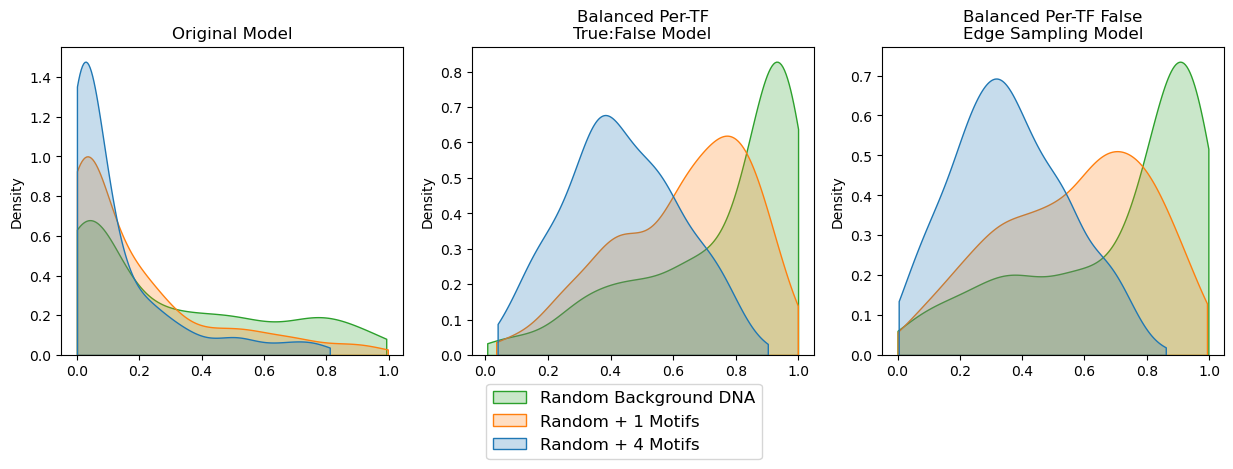

In [3]:
new_labels = {
    "p_background": "Random Background DNA",
    "p_one_copy": "Random + 1 Motifs",
    "p_max_copies": "Random + 4 Motifs"
}

original_model_df.rename(columns=new_labels, inplace=True)
balanced_model_df.rename(columns=new_labels, inplace=True)
balanced_random_model_df.rename(columns=new_labels, inplace=True)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
sns.kdeplot(original_model_df[new_labels.values()], ax=axes[0], fill=True, cut=0, legend=False)

axes[0].set_title("Original Model")

sns.kdeplot(balanced_model_df[list(new_labels.values())], ax=axes[1], fill=True, cut=0, legend=False)
axes[1].set_title("Balanced Per-TF\nTrue:False Model")

sns.kdeplot(balanced_random_model_df[list(new_labels.values())], ax=axes[2], fill=True, cut=0, legend=False)
axes[2].set_title("Balanced Per-TF False\nEdge Sampling Model")

fig.legend(labels=list(new_labels.values()), loc="lower center", bbox_to_anchor=(0.5, -0.15), borderaxespad=0., fontsize=12)

plt.savefig(PROJECT_DIR / "new_plots" / "tf_dna_binding_evaluation" / "tf_motif_binding_kde.png", dpi=300, bbox_inches="tight")

In [4]:
def print_model_statistics(model_df, model_name):
    print(f"Statistics for {model_name}:")
    for col in new_labels.values():
        mean = model_df[col].mean()
        std = model_df[col].std()
        print(f"{col} - Mean: {mean:.4f}, Standard Deviation: {std:.4f}")
    print("\n")

print_model_statistics(original_model_df, "Original Model")
print_model_statistics(balanced_model_df, "Balanced Per-TF True:False Model")
print_model_statistics(balanced_random_model_df, "Balanced Per-TF False Edge Sampling Model")

Statistics for Original Model:
Random Background DNA - Mean: 0.1228, Standard Deviation: 0.1794
Random + 1 Motifs - Mean: 0.1831, Standard Deviation: 0.2344
Random + 4 Motifs - Mean: 0.2879, Standard Deviation: 0.3082


Statistics for Balanced Per-TF True:False Model:
Random Background DNA - Mean: 0.4358, Standard Deviation: 0.1856
Random + 1 Motifs - Mean: 0.6282, Standard Deviation: 0.2195
Random + 4 Motifs - Mean: 0.7478, Standard Deviation: 0.2495


Statistics for Balanced Per-TF False Edge Sampling Model:
Random Background DNA - Mean: 0.3608, Standard Deviation: 0.1836
Random + 1 Motifs - Mean: 0.5661, Standard Deviation: 0.2413
Random + 4 Motifs - Mean: 0.7026, Standard Deviation: 0.2780




### Plotting and Helper Functions

In [5]:
def detach(tensor):
    if isinstance(tensor, torch.Tensor):
        return tensor.detach().cpu().numpy()
    else:
        return tensor


def unmask(tensor, mask):
    if isinstance(tensor, torch.Tensor) and isinstance(mask, torch.Tensor):
        return tensor[mask == 1]
    else:
        raise ValueError("Both tensor and mask must be torch.Tensor instances.")


def plot_single_row_heatmap(values, col_values, title):
    fig, ax = plt.subplots(figsize=(6, 0.5))

    if isinstance(values, torch.Tensor):
        values_plotting = values.detach().cpu().numpy()
    else:
        values_plotting = torch.tensor(values).unsqueeze(1).numpy()

    im = ax.imshow(
        values_plotting.T,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
    )

    tick_positions = np.linspace(0, len(col_values) - 1, 9, dtype=int)
    ax.set_xticks(tick_positions)

    tick_labels = [f"{col_values[i]:.1f}" for i in tick_positions]
    ax.set_xlabel("Expression Input", fontsize=14, labelpad=10)

    ax.set_xticklabels(tick_labels, fontsize=12)
    ax.set_yticklabels(["1"], fontsize=12)
    ax.set_title(title, fontsize=16, pad=10)
    # fig.colorbar(im, ax=ax, label="Projection output")
    ax.xaxis.set_label_position('top') 

    ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False, left=False, labelleft=False)

    plt.show()
    
    
def plot_single_column_heatmap(values, row_values, title):
    fig, ax = plt.subplots(figsize=(1, 8))

    if isinstance(values, torch.Tensor):
        values_plotting = values.detach().cpu().numpy()
    else:
        values_plotting = torch.tensor(values).unsqueeze(1).numpy()
        
    im = ax.imshow(
        values_plotting,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
    )

    tick_positions = np.linspace(0, len(row_values) - 1, 9, dtype=int)
    ax.set_yticks(tick_positions)

    tick_labels = [f"{row_values[i]:.1f}" for i in tick_positions]
    ax.set_ylabel("Projection dimension", fontsize=14, labelpad=10)

    ax.set_yticklabels(tick_labels, fontsize=12)
    ax.set_title(title, fontsize=16, pad=10)
    # fig.colorbar(im, ax=ax, label="Projection output")
    ax.xaxis.set_label_position('top') 

    ax.tick_params(top=False, labeltop=False, bottom=False, labelbottom=False, left=False, labelleft=False)

    plt.show()


def plot_projected_expression(
    projection_dict,
    keep_square=False,
    height=8,
    ncols=3,
    xlabel=None,
    ylabel=None,
    cmap="viridis",
):
    if not projection_dict:
        raise ValueError("projection_dict must not be empty")

    # Prepare matrices without modifying the original dictionary.
    prepared = []
    for title, (projected, inputs) in projection_dict.items():
        if projected.ndim == 3 and projected.shape[0] == 1:
            projected = projected.squeeze(0)

        if projected.ndim != 2:
            raise ValueError(
                f"{title}: expected a 2D projection or a singleton batch, "
                f"got shape {tuple(projected.shape)}"
            )

        if any(size == 0 for size in projected.shape):
            raise ValueError(f"{title}: projection dimensions must be nonzero")

        prepared.append((title, projected.T, inputs))

    # Number of subplot columns and rows
    if ncols < 1:
        raise ValueError("ncols must be positive")

    ncols = min(int(ncols), len(prepared))
    nrows = (len(prepared) + ncols - 1) // ncols

    # Physical cell dimensions, in inches
    cell_width = 0.15
    cell_height = 0.15

    # Margins and spacing, in inches
    left, right = 1.0, 0.3
    bottom, top = 0.8, 1.2
    hgap = 1.0
    vgap = 1.5  # Room for titles and x-axis labels between rows

    shapes = [matrix.shape for _, matrix, _ in prepared]

    # Each layout column/row accommodates its largest heatmap.
    column_widths = [
        max(
            shapes[i][1] * cell_width
            for i in range(col, len(prepared), ncols)
        )
        for col in range(ncols)
    ]

    row_heights = [
        max(
            shapes[i][0] * cell_height
            for i in range(row * ncols, min((row + 1) * ncols, len(prepared)))
        )
        for row in range(nrows)
    ]

    # Scale all heatmap cells uniformly to fit the total height limit.
    fixed_height = bottom + top + vgap * (nrows - 1)
    if height <= fixed_height:
        raise ValueError(
            f"height must exceed {fixed_height:.1f} inches "
            "to accommodate margins and spacing; increase height or ncols"
        )

    scale = min(1.0, (height - fixed_height) / sum(row_heights))
    
    title_fontsize = max(6, 16 * scale)
    label_fontsize = max(6, 14 * scale)
    tick_fontsize = max(5, 12 * scale)

    column_widths = [width * scale for width in column_widths]
    row_heights = [row_height * scale for row_height in row_heights]

    plot_widths = [cols * cell_width * scale for rows, cols in shapes]
    plot_heights = [rows * cell_height * scale for rows, cols in shapes]

    fig_width = left + sum(column_widths) + hgap * (ncols - 1) + right
    fig_height = fixed_height + sum(row_heights)

    fig = plt.figure(figsize=(fig_width, fig_height))
    axes = []

    row_top = fig_height - top

    for row in range(nrows):
        x = left

        for col in range(ncols):
            i = row * ncols + col
            if i >= len(prepared):
                break

            plot_width = plot_widths[i]
            plot_height = plot_heights[i]

            ax = fig.add_axes([
                x / fig_width,
                (row_top - plot_height) / fig_height,
                plot_width / fig_width,
                plot_height / fig_height,
            ])
            axes.append(ax)

            x += column_widths[col] + hgap

        row_top -= row_heights[row] + vgap

    for ax, (title, matrix, inputs), plot_height in zip(
        axes, prepared, plot_heights
    ):
        ax.imshow(
            matrix,
            aspect="equal" if keep_square else "auto",
            interpolation="nearest",
            cmap=cmap,
        )

        if inputs is not None and len(inputs) > 0:
            tick_positions = np.unique(
                np.linspace(0, len(inputs) - 1, 9, dtype=int)
            )
            ax.set_xticks(tick_positions)
            ax.set_xticklabels(
                [f"{inputs[j]:.1f}" for j in tick_positions],
                fontsize=tick_fontsize,
            )
            ax.set_xlabel(
                xlabel if xlabel is not None else "Expression Input",
                fontsize=label_fontsize,
                labelpad=10,
            )
            ax.tick_params(
                axis="x",
                top=True,
                labeltop=True,
                bottom=False,
                labelbottom=False,
            )
        else:
            ax.set_xticks([])
            if xlabel is not None:
                ax.set_xlabel(xlabel, fontsize=label_fontsize, labelpad=10)

        ax.tick_params(axis="y", labelsize=tick_fontsize)
        
        label = ylabel if ylabel is not None else "Projection size"

        # Remove existing newlines, then wrap only for short heatmaps.
        label = " ".join(label.split())

        if plot_height < 1.5:
            label = label.replace(" ", "\n")

        ax.set_ylabel(label, fontsize=label_fontsize, wrap=False)
                
        
        ax.set_title(title, fontsize=title_fontsize, pad=10)
        ax.xaxis.set_label_position("top")

    plt.show()

### Loading the TF-DNA binding model and inputs

In [6]:
species = "mm10"

mm10_tf_dna_path = CHKPT_DIR / "tf_dna_mm10_3925194" / "epoch_21.ckpt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tf_dna_input_cache_dir = PROJECT_DIR / "cached_data" / species / "tf_dna_cache"

tf_dna_data = utils.load_tf_dna_data(tf_dna_input_cache_dir)

# Unpack all returned tensors
edge_tf_idx_tensor, edge_peak_idx_tensor, edge_labels_tensor, \
    tf_embeddings_tensor, tf_mask_tensor, one_hot_peaks = tf_dna_data

# Name to ID dictionaries
tf_name_to_idx_df = pd.read_csv(tf_dna_input_cache_dir / "tf_name_to_idx.csv")
peak_id_to_idx_df = pd.read_csv(tf_dna_input_cache_dir / "peak_id_to_idx.csv")

tf_name_to_idx_dict = tf_name_to_idx_df.set_index("tf_name")["tf_idx"].to_dict()
peak_name_to_idx_dict = peak_id_to_idx_df.set_index("peak_id")["peak_idx"].to_dict()

tf_idx_to_name = {idx: name for name, idx in tf_name_to_idx_dict.items()}
peak_idx_to_name = {idx: name for name, idx in peak_name_to_idx_dict.items()}

# Load the trained TF-DNA model
tf_dna_model = utils.load_tf_dna_model(
    tf_dna_model_path=mm10_tf_dna_path,
    tf_embeddings_tensor=tf_embeddings_tensor,
    tf_mask_tensor=tf_mask_tensor,
    device=device,
    compile_model=True
)
tf_dna_model

2026-10-23 11:26:52,219 - INFO - Compiling loaded TF-DNA core model.


LitTFPeakBindingModel(
  (model): OptimizedModule(
    (_orig_mod): TFPeakBindingModel(
      (tf_encoder): Sequential(
        (0): Linear(in_features=128, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.3, inplace=False)
        (3): Linear(in_features=128, out_features=128, bias=True)
      )
      (peak_encoder): Sequential(
        (0): Conv1d(4, 64, kernel_size=(15,), stride=(1,), padding=(7,))
        (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): GELU(approximate='none')
        (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
        (4): Conv1d(64, 128, kernel_size=(9,), stride=(1,), padding=(4,))
        (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (6): GELU(approximate='none')
        (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
        (8): Conv1d(128, 128, kernel_si

In [7]:
dataset = utils.TFPeakEdgeDataset(
    edge_tf_idx=edge_tf_idx_tensor,
    edge_peak_idx=edge_peak_idx_tensor,
    edge_labels=edge_labels_tensor,
    peak_tensor=one_hot_peaks
)

item = dataset[0]
item

{'tf_idx': tensor(167),
 'peak_idx': tensor(9193136),
 'peak_embedding': tensor([[0, 0, 1, 0],
         [0, 0, 1, 0],
         [1, 0, 0, 0],
         ...,
         [0, 1, 0, 0],
         [1, 0, 0, 0],
         [0, 0, 1, 0]], dtype=torch.uint8),
 'label': tensor(0.)}

### Run a model prediction

In [11]:
parameter = next(tf_dna_model.parameters())
device = parameter.device
dtype = parameter.dtype

tf_embedding = tf_embeddings_tensor[dataset[0]["tf_idx"]].unsqueeze(0).to(device=device, dtype=dtype)
tf_mask = tf_mask_tensor[dataset[0]["tf_idx"]].unsqueeze(0).to(device=device, dtype=torch.bool)
peak_onehot = one_hot_peaks[dataset[0]["peak_idx"]].unsqueeze(0).to(device=device, dtype=dtype)

tf_dna_model.eval()

with torch.inference_mode():
    output_logit = tf_dna_model(tf_embedding, tf_mask, peak_onehot)
    output_prob = torch.sigmoid(output_logit)

print(f"TF {dataset[0]['tf_idx']} binds to peak {dataset[0]['peak_idx']} with probability {output_prob.item():.4f}")


Iteration 1: TF 16 binds to peak 6962113 with probability 0.9353
Iteration 4: TF 421 binds to peak 5956308 with probability 0.7204
Iteration 5: TF 20 binds to peak 202006 with probability 0.6873
Iteration 6: TF 376 binds to peak 5254494 with probability 0.9915
Iteration 7: TF 226 binds to peak 2665672 with probability 0.6176
Iteration 8: TF 300 binds to peak 7639156 with probability 0.7525
Iteration 9: TF 162 binds to peak 1542275 with probability 0.8146
Iteration 10: TF 211 binds to peak 1474944 with probability 0.7761
Iteration 12: TF 339 binds to peak 7902994 with probability 0.9364
Iteration 14: TF 65 binds to peak 4707501 with probability 0.9380


### TF embedding and peak-onehot tensor structure

--- General Information ---
  - Number of Edges: 13,550,720
     - True edges: 6,775,360
     - False edges: 6,775,360
  - Number of TFs: 428
  - Number of DNA Sites: 9,928,560


--- Edge TF and DNA Indices ---
Edge TF index tensor torch.Size([13550720])
  - First Edge's TF index: 167
  - First Edge's TF name: Insm1

Edge peak index tensor torch.Size([13550720])
  - First Edge's peak index: 9193136
  - First Edge's DNA location: chr9:124256355-124256604


--- TF Embedding and Mask Tensors ---
TF embedding tensor (torch.Size([443, 3966, 128]))
  - Number of Batches: 443
  - Largest TF length: 3,966
  - Embedding dimension: 128

TF padding mask tensor (torch.Size([443, 3966]))
  - Number of Batches: 443
  - Largest TF length: 3,966

TF padding mask for the first TF (torch.Size([3966]))
  - 521 valid positions (1s)
  - 2,924 padded positions (0s)


--- One-hot Peak Tensor ---
One-hot peak tensor (shape: torch.Size([9928560, 256, 4])):
  - Number of Peaks: 9928560
  - Peak length: 256
  - 

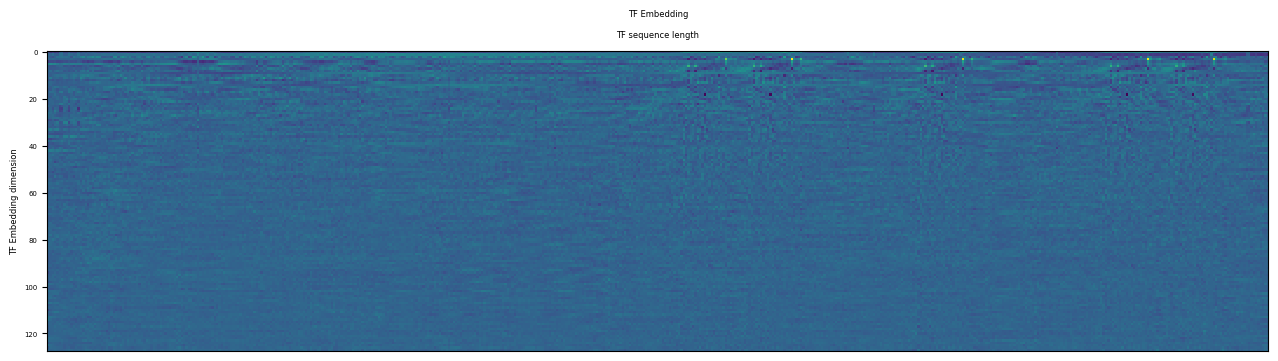

In [8]:
print(f"--- General Information ---")
print(f"  - Number of Edges: {len(edge_tf_idx_tensor):,}")
print(f"     - True edges: {len(torch.where(edge_labels_tensor == 1)[0]):,}")
print(f"     - False edges: {len(torch.where(edge_labels_tensor == 0)[0]):,}")
print(f"  - Number of TFs: {len(edge_tf_idx_tensor.unique()):,}")
print(f"  - Number of DNA Sites: {len(edge_peak_idx_tensor.unique()):,}")

print("\n\n--- Edge TF and DNA Indices ---")
print(f"Edge TF index tensor {edge_tf_idx_tensor.shape}")
print(f"  - First Edge's TF index: {edge_tf_idx_tensor[0]}")
print(f"  - First Edge's TF name: {tf_idx_to_name[edge_tf_idx_tensor[0].item()]}")

print(f"\nEdge peak index tensor {edge_peak_idx_tensor.shape}")
print(f"  - First Edge's peak index: {edge_peak_idx_tensor[0]}")
print(f"  - First Edge's DNA location: {peak_idx_to_name[edge_peak_idx_tensor[0].item()]}")

print("\n\n--- TF Embedding and Mask Tensors ---")
print(f"TF embedding tensor ({tf_embeddings_tensor.shape})")
print(f"  - Number of Batches: {tf_embeddings_tensor.shape[0]:,}")
print(f"  - Largest TF length: {tf_embeddings_tensor.shape[1]:,}")
print(f"  - Embedding dimension: {tf_embeddings_tensor.shape[2]:,}")

# print(tf_embeddings_tensor[edge_tf_idx_tensor[0], :5, :5])

print(f"\nTF padding mask tensor ({tf_mask_tensor.shape})")
print(f"  - Number of Batches: {tf_mask_tensor.shape[0]:,}")
print(f"  - Largest TF length: {tf_mask_tensor.shape[1]:,}")

mask = tf_mask_tensor[edge_tf_idx_tensor[0]]
num_mask_true_positions = len(torch.where(mask == 1)[0])
num_mask_false_positions = len(torch.where(mask == 0)[0]) - num_mask_true_positions
print(f"\nTF padding mask for the first TF ({mask.shape})")
print(f"  - {num_mask_true_positions:,} valid positions (1s)")
print(f"  - {num_mask_false_positions:,} padded positions (0s)")

print("\n\n--- One-hot Peak Tensor ---")
print(f"One-hot peak tensor (shape: {one_hot_peaks.shape}):")
print(f"  - Number of Peaks: {one_hot_peaks.shape[0]}")
print(f"  - Peak length: {one_hot_peaks.shape[1]}")
print(f"  - One-hot encoding dimension: {one_hot_peaks.shape[2]}")
first_peak_sequence = utils.get_peak_sequence(edge_peak_idx_tensor[0], one_hot_peaks)
print(f"  - First peak location: {peak_idx_to_name[edge_peak_idx_tensor[0].item()]}")
print(f"  - First peak sequence ({len(first_peak_sequence)} bp): {first_peak_sequence[:10]}...{first_peak_sequence[-10:]}")

unmasked_tf_tensor = tf_embeddings_tensor[edge_tf_idx_tensor[0]][mask]


tf_embedding_dict = {
    "TF Embedding": (unmasked_tf_tensor, None)
}
plot_projected_expression(
    tf_embedding_dict, 
    keep_square=False, 
    height=5, 
    xlabel="TF sequence length", 
    ylabel="TF Embedding dimension"
    )

### Evaluate TF-DNA binding to random DNA sequences

In [ ]:
def generate_random_background_dna_sequence(background_nuc_freq: dict) -> str:
    """
    Generate a random DNA sequence based on specified nucleotide frequencies.

    Parameters:
    background_nuc_freq (dict): A dictionary with nucleotides as keys ('A', 'C', 'G', 'T') 
                                 and their corresponding frequencies as values.

    Returns:
    str: A randomly generated DNA sequence.
    """
    nucleotides = list(background_nuc_freq.keys())
    frequencies = list(background_nuc_freq.values())
    
    # Normalize frequencies to ensure they sum to 1
    total = sum(frequencies)
    normalized_frequencies = [freq / total for freq in frequencies]
    
    # Generate a random DNA sequence of length 256
    sequence_length = 256
    random_sequence = np.random.choice(nucleotides, size=sequence_length, p=normalized_frequencies)
    
    return ''.join(random_sequence)

mm10_bg = {
    'A': 0.2925, 
    'T': 0.2925, 
    'G': 0.2075, 
    'C': 0.2075
}

In [13]:
tf_dna_model.eval()
tf_dna_model.to(device)

num_tfs = tf_embeddings_tensor.shape[0]
num_rand_seqs = 100

num_tfs = min(tf_embeddings_tensor.shape[0], num_tfs)
rand_tf_indices = np.random.choice(num_tfs, size=num_rand_seqs, replace=True)

# Generate random background DNA sequences and convert them to one-hot encoding
random_dna = torch.tensor(
    np.array([utils.onehot_dna_sequence(generate_random_background_dna_sequence(mm10_bg)) for _ in range(num_rand_seqs)]),
    device=device,
    dtype=dtype
    )

# Load the motifs for the selected TFs from the CIS-BP database
tf_names = [tf_idx_to_name[idx] for idx in rand_tf_indices]
motif_data_dir = DATA_DIR / "databases" / "motif_information" / "mm10"
motifs = utils.load_cisbp_motifs(motif_data_dir, tf_names, include_inferred=True)
print(f"Loaded {len(motifs)} motifs for TFs in the dataset.")

# Calculate each TF's binding probabilities to the random background DNA sequences
tf_random_binding_probs = {}

for tf_idx in tqdm(rand_tf_indices, ncols=100, desc="TF Random DNA Binding"):
    # Expand the TF embedding and mask tensors to match the number of random DNA sequences
    tf_embedding = tf_embeddings_tensor[tf_idx].expand(num_rand_seqs, -1, -1).to(device=device, dtype=dtype)
    tf_mask = tf_mask_tensor[tf_idx].expand(num_rand_seqs, -1).to(device=device, dtype=torch.bool)

    with torch.inference_mode():
        output_logits = tf_dna_model(tf_embedding, tf_mask, random_dna)
        output_probs = torch.sigmoid(output_logits)

    tf_random_binding_probs[tf_idx] = (output_probs.detach().cpu().numpy(), random_dna.shape[0])

Loaded 83 motifs for TFs in the dataset.


TF Random DNA Binding: 100%|██████████████████████████████████████| 100/100 [00:14<00:00,  6.72it/s]


In [86]:
def generate_onehot_from_pwm(motifs, selected_tf_name):
    """
    Generate a one-hot encoded sequence from the PWM of the selected TF.

    Parameters:
    motifs (dict): A dictionary containing motifs for various TFs.
    selected_tf_name (str): The name of the selected TF.

    Returns:
    np.ndarray: A one-hot encoded sequence based on the PWM of the selected TF.
    """
    # Get the nucleotide frequency matrix (PWM) for the selected TF
    tf_motif = motifs[selected_tf_name]["pwm"]

    # Generate random numbers with the same shape as the motif
    rand_nums = np.random.rand(tf_motif.shape[0], tf_motif.shape[1])

    # Multiply the motif by the random numbers to create a weighted random array
    weighted_rand_arr = tf_motif * rand_nums

    # Take the maximum value in each row of the weighted random array
    row_max = np.max(weighted_rand_arr, axis=1, keepdims=True)

    # Set the maximum value in each row to 1 and all other values to 0
    result = np.where(weighted_rand_arr == row_max, 1, 0)

    return result

selected_tf_name = "ELF5"
onehot_sequence_from_pwm = generate_onehot_from_pwm(motifs, selected_tf_name)

nuc_ids = np.argmax(onehot_sequence_from_pwm, axis=-1)
peak_nuc_key = ["A", "C", "G", "T"]
pwm_seq = "".join([peak_nuc_key[nuc_id] for nuc_id in nuc_ids])

print(f"One-hot encoded sequence from PWM for {selected_tf_name}:")
print(onehot_sequence_from_pwm)
print(f"Corresponding DNA sequence: {pwm_seq}")

rand_seq = generate_random_background_dna_sequence(mm10_bg)
print(f"Random background DNA sequence: {rand_seq}")


One-hot encoded sequence from PWM for ELF5:
[[0 0 1 0]
 [0 0 1 0]
 [0 0 1 0]
 [1 0 0 0]
 [0 0 1 0]
 [1 0 0 0]
 [1 0 0 0]
 [0 0 1 0]
 [0 0 1 0]
 [1 0 0 0]
 [1 0 0 0]
 [0 0 1 0]
 [1 0 0 0]
 [1 0 0 0]
 [1 0 0 0]]
Corresponding DNA sequence: GGGAGAAGGAAGAAA
Random background DNA sequence: TTGTACGCAGCAATTGGCTAATTTGACCGGACGGTCTGGAACTGCGATTATCTTATATCGCTCCAAGTGAAAATGTATTTATCTGCCAATTCACTCCTGGATCTGCAAATATTAGTGGCACCATGCTGCCGTGGAATTTATGGCCTTCTCTAGTGACCGTCACAGACGCATGGATTCAAGCTTTCAGATCTTGTGCCGGTCTAGCCTCCTTATAGTTTAGAACACATCGGTTTAGAGAATTGCAGCTTATTGGCAA


In [259]:
seq = np.zeros((12), dtype=int)

motif_dict = {
"a" : np.array([-1, -1,-1]),
"b" : np.array([-2, -2, -2]),
"c" : np.array([-3, -3]),
"d" : np.array([-4, -4, -4, -4])
}

print(f"Initial sequence: {seq}")

occupied_positions = np.zeros_like(seq, dtype=bool)
start_positions = []

for motif in motif_dict.keys():
    print(f"\nPlacing motif {motif} with seq {motif_dict[motif]}")
    motif_arr = motif_dict[motif]
    # Positions where motif b would not go past the sequence length
    start_options = np.arange(0, len(seq) - len(motif_arr) + 1)
    print(f"  - Unoccupied positions: {np.where(occupied_positions == False, 1, 0)}")

    # Positions where b does not overlap with motif a's positions
    start_options = np.setdiff1d(start_options, np.where(occupied_positions == True))
    print(f"  - Start options before seq end: {start_options}")

    # Positions where motif b's length would not cause it to collide with motif a
    for start_position in start_positions:
        if start_position > 0:
            collide_w_occupied = np.arange(start_position - len(motif_arr) + 1, start_position) # Start positions that would cause collision
            
            if len(np.intersect1d(start_options, collide_w_occupied)) > 0:
                start_options = np.setdiff1d(start_options, collide_w_occupied) # Remove from b's start options
            
                print(f"    - Positions {collide_w_occupied} would collide with the start of another motif")
        
    print(f"  - Final positions for motif {motif}: {start_options}")
    
    if len(start_options) == 0:
        print(f"No room for motif {motif} with length {len(motif_arr)}")
        continue

    rand_start_loc = np.random.choice(start_options)
    start_positions.append(rand_start_loc)
    print(f"  - Random start position for motif {motif}: {rand_start_loc}")

    motif_positions = np.arange(rand_start_loc, rand_start_loc + len(motif_arr))
    occupied_positions[motif_positions] = True
    print(f"  - Selected positions for motif {motif}: {motif_positions}")

    seq[motif_positions] = motif_arr
    
print(f"Seq + motifs: {seq}")


Initial sequence: [0 0 0 0 0 0 0 0 0 0 0 0]

Placing motif a with seq [-1 -1 -1]
  - Unoccupied positions: [1 1 1 1 1 1 1 1 1 1 1 1]
  - Start options before seq end: [0 1 2 3 4 5 6 7 8 9]
  - Final positions for motif a: [0 1 2 3 4 5 6 7 8 9]
  - Random start position for motif a: 3
  - Selected positions for motif a: [3 4 5]

Placing motif b with seq [-2 -2 -2]
  - Unoccupied positions: [1 1 1 0 0 0 1 1 1 1 1 1]
  - Start options before seq end: [0 1 2 6 7 8 9]
    - Positions [1 2] would collide with the start of another motif
  - Final positions for motif b: [0 6 7 8 9]
  - Random start position for motif b: 8
  - Selected positions for motif b: [ 8  9 10]

Placing motif c with seq [-3 -3]
  - Unoccupied positions: [1 1 1 0 0 0 1 1 0 0 0 1]
  - Start options before seq end: [0 1 2 6 7]
    - Positions [2] would collide with the start of another motif
    - Positions [7] would collide with the start of another motif
  - Final positions for motif c: [0 1 6]
  - Random start position 

In [ ]:
dna_positions = np.arange(0, len(rand_seq))
motif_1_positions = np.arange(0, len(dna_positions) - len(pwm_seq))
print(motif_1_positions)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240]


In [ ]:

# Calculate a random position to insert the motif sequence into the random background DNA sequence
rand_seq_pos1 = np.random.randint(0, len(rand_seq) - len(pwm_seq) + 1)
rand_seq_pos2 = np.random.randint(0, len(rand_seq) - len(pwm_seq) + 1)

# Get the span of the motif insertion positions
rand_seq_pos1_span = (rand_seq_pos1, rand_seq_pos1 + len(pwm_seq) - 1)
rand_seq_pos2_span = (rand_seq_pos2, rand_seq_pos2 + len(pwm_seq) - 1)

print(f"Random motif insertion positions: {rand_seq_pos1_span[0]}-{rand_seq_pos1_span[1]} and {rand_seq_pos2_span[0]}-{rand_seq_pos2_span[1]}")

# If the two motif positions overlap, adjust the second position to avoid overlap
def overlap_length(start1, end1, start2, end2):
    return max(0, min(end1, end2) - max(start1, start2))

seq_overlap = overlap_length(rand_seq_pos1_span[0], rand_seq_pos1_span[1], rand_seq_pos2_span[0], rand_seq_pos2_span[1])

if seq_overlap > 0:
    print(f"Warning: The two motif positions overlap by {seq_overlap} bases. Adjusting the second start position to {rand_seq_pos2 + seq_overlap + 1} avoid overlap.")
    rand_seq_pos2 += seq_overlap + 1
    
if rand_seq_pos2 + len(pwm_seq) > len(rand_seq):
    rand_seq_pos2 = len(rand_seq) - len(pwm_seq)
    print(f"Adjusted second motif position to {rand_seq_pos2} to fit within the sequence length.")
    
    
# Add the first pwm sequence to the random background DNA sequence at the first random position
combined_seq = rand_seq[:rand_seq_pos1] + pwm_seq + rand_seq[rand_seq_pos1 + len(pwm_seq):]

# Add the second pwm sequence to the combined sequence at the second random position
combined_seq = combined_seq[:rand_seq_pos2] + pwm_seq + combined_seq[rand_seq_pos2 + len(pwm_seq):]

# Ensure the combined sequence length is 256 bases
if len(combined_seq) > 256:
    combined_seq = combined_seq[:256]

motif_center = rand_seq_pos1 + len(pwm_seq) // 2
peak_center = len(rand_seq) // 2
motif_distance_from_peak_center = motif_center - peak_center


print(f"Motif center position in combined sequence: {motif_center}")
print(f"Peak center position in combined sequence: {peak_center}")
print(f"Distance of motif center from peak center: {motif_distance_from_peak_center}")
print(f"Combined sequence with motif inserted in positions {rand_seq_pos1}-{rand_seq_pos1 + len(pwm_seq) - 1}: {combined_seq}")
print(f"Length of combined sequence: {len(combined_seq)}")

onehot_combined_seq = torch.tensor(utils.onehot_dna_sequence(combined_seq), device=device, dtype=dtype).unsqueeze(0)

tf_idx = tf_name_to_idx_dict[selected_tf_name.capitalize()]
tf_embedding = tf_embeddings_tensor[tf_idx].expand(1, -1, -1).to(device=device, dtype=dtype)
tf_mask = tf_mask_tensor[tf_idx].expand(1, -1).to(device=device, dtype=torch.bool)

with torch.inference_mode():
    output_logits = tf_dna_model(tf_embedding, tf_mask, onehot_combined_seq)
    output_probs = torch.sigmoid(output_logits)

print(f"Binding probabilities for TF {selected_tf_name} to random DNA with motif: {output_probs.detach().cpu().numpy()}")

In [ ]:
num_tf_edges = [len(torch.where(edge_tf_idx_tensor == i)[0]) for i in tf_random_binding_probs.keys()]
tf_true_edge_counts = [len(torch.argwhere((edge_tf_idx_tensor == i) & (edge_labels_tensor == 1))) for i in tf_random_binding_probs.keys()]
tf_false_edge_counts = [len(torch.argwhere((edge_tf_idx_tensor == i) & (edge_labels_tensor == 0))) for i in tf_random_binding_probs.keys()]

Loaded 87 motifs for TFs in the dataset.


In [ ]:
print("\n\n--- Random Background DNA Binding Probabilities ---")
tf_random_binding_df = pd.DataFrame({
    "TF_idx": list(tf_random_binding_probs.keys()),
    "TF_name": tf_names,
    "binding_mean": [probs.mean() for probs, _ in tf_random_binding_probs.values()],
    "binding_std": [probs.std() for probs, _ in tf_random_binding_probs.values()],
    "num_sequences": [dna_count for _, dna_count in tf_random_binding_probs.values()],
    "tf_motif": [motifs.get(tf_name.upper(), None)["pwm"] for tf_name in tf_names],
    "tf_family": [motifs.get(tf_name.upper(), None)["motif_type"] for tf_name in tf_names],
    "num_tf_edges": num_tf_edges,
    "num_true_edges": tf_true_edge_counts,
    "num_false_edges": tf_false_edge_counts,
})
tf_random_binding_df



--- Random Background DNA Binding Probabilities ---


,TF_idx,TF_name,binding_mean,binding_std,num_sequences,tf_motif,num_tf_edges,num_true_edges,num_false_edges
0,112,Zfp64,0.559857,0.192277,100,"{'pwm': [[0.0925929074070926, 0.11481488518511...",3010,1505,1505
1,173,Yy2,0.315083,0.194092,100,"{'pwm': [[0.6754186772636959, 0.06670451319897...",0,0,0
2,363,Nr1h2,0.210488,0.186538,100,"{'pwm': [[0.423, 0.001, 0.568, 0.008], [0.02, ...",40000,20000,20000
3,97,Dpf3,0.136132,0.108134,100,"{'pwm': [[0.076046289045506, 0.121291220743061...",27730,13865,13865
4,203,Etv2,0.195045,0.112895,100,"{'pwm': [[0.5807860262008735, 0.13537117903930...",40000,20000,20000
...,...,...,...,...,...,...,...,...,...
85,151,Zfp961,0.493504,0.288013,100,"{'pwm': [[0.012693935119887196, 0.014104372355...",3968,1984,1984
86,82,Fos,0.284474,0.146095,100,"{'pwm': [[0.478, 0.146, 0.374, 0.002], [0.0, 0...",40000,20000,20000
87,275,Six4,0.082443,0.093801,100,"{'pwm': [[0.9468655325099045, 0.02307154509438...",40000,20000,20000
88,321,Mbd3,0.299748,0.160710,100,"{'pwm': [[0.10600113372769632, 0.7217821295791...",40000,20000,20000


In [51]:
def all_pairs_pwm_similarity(pwm_list):
    """[N, N] best-alignment motif similarity in [-1, 1]; 1.0 == identical motif.

        score(shift) = sum_i pearson(a[i + shift], b[i]) / (len_a + len_b - overlap)

    maximised over every ungapped shift and both strands. The union-length
    denominator charges for the non-overlapping tails, so a short chance match
    between two long motifs cannot outscore a real full-length match.

    Vectorised as one matmul per (shift, strand) -- ~13 s for 360 motifs, versus
    hours for a Python loop over pairs.
    """
    lens = np.array([len(p) for p in pwm_list])
    pad = int(lens.max())
    n = len(pwm_list)
    
    def _encode_pwms(pwms, pad):
        """[N, pad, 4] centered + unit-normalised columns, plus [N, pad] real-column mask.

        Centering each column makes a per-column dot product exactly the Pearson
        correlation of the two 4-vectors. Cosine on raw probabilities instead scores
        every pair of near-uniform columns at ~1.0.
        """
        Z = np.zeros((len(pwms), pad, 4))
        M = np.zeros((len(pwms), pad))
        for i, pwm in enumerate(pwms):
            col = pwm - pwm.mean(axis=1, keepdims=True) # Center each column by subtracting its mean
            
            # Normalize each position to unit length (z = (xi - mean) / ||xi - mean||)
            # (dot product between two centered and normalized columns is the Pearson correlation)
            nrm = np.linalg.norm(col, axis=1, keepdims=True) 
            Z[i, : len(pwm)] = np.divide(col, nrm, out=np.zeros_like(col), where=nrm > 1e-12)
            
            # Pad the mask to indicate which columns are real (1) and which are padded (0)
            # based on the max length of the PWMs
            M[i, : len(pwm)] = 1.0
        return Z, M

    # Encode the PWMs and their reverse complements
    Zf, M = _encode_pwms(pwm_list, pad)
    Zr, _ = _encode_pwms([p[::-1, ::-1] for p in pwm_list], pad)  # reverse complement

    # Calculate Pearson correlation for each pair of PWMs, considering all shifts and both strands
    len_sum = lens[:, None] + lens[None, :] # Denominator for each comparison: len_a + len_b - overlap
    best = np.full((n, n), -np.inf)

    for Z_other in (Zf, Zr): # Compare forward and reverse complement
        B = Z_other.reshape(n, -1) # flatten for matrix multiplication (N, pad, 4) -> (N, pad*4)
        
        # Try every possible sliding window shift between the two PWMs
        for shift in range(-(pad - 1), pad):
            Zs, Ms = np.zeros_like(Zf), np.zeros_like(M)
            
            # Get the overlapping region of the two PWMs based on the current shift
            if shift >= 0:
                Zs[:, shift:], Ms[:, shift:] = Zf[:, : pad - shift], M[:, : pad - shift]
            else:
                Zs[:, : pad + shift], Ms[:, : pad + shift] = Zf[:, -shift:], M[:, -shift:]
                
            # Calculate the overlap as the dot product of the masks (number of overlapping columns)
            overlap = Ms @ M.T
            
            # Calculate the score for each pair of PWMs based on the dot product of the encoded columns
            score = (Zs.reshape(n, -1) @ B.T) / np.maximum(len_sum - overlap, 1.0)
            
            # Update the best score for each pair of PWMs if the current score is higher
            np.maximum(best, score, out=best)

    # Fill the diagonal with 1.0 since each PWM is identical to itself
    np.fill_diagonal(best, 1.0)
    return best

def plot_similarity_heatmap(similarity_matrix, mask_lower_triangle=False, title=""):
    """
    Plot a heatmap of the cosine similarity between mean-pooled DBD embeddings.
    
    Args:
        similarity_matrix (np.ndarray): A square matrix of cosine similarities.
        mask_lower_triangle (bool): A boolean specify whether to hide the lower triangle of the heatmap.
    """
    if mask_lower_triangle is True:
        mask_lower_triangle = np.tril(
            np.ones_like(similarity_matrix, dtype=bool),
            k=0,
        )
    else:
        mask_lower_triangle = None

    fig, ax = plt.subplots(figsize=(4, 4))
    sns.heatmap(
        similarity_matrix,
        mask=mask_lower_triangle,
        cmap="viridis",
        cbar_kws={"label": "Cosine Similarity"},
        ax=ax,
        xticklabels=False,
        yticklabels=False,
        cbar=False,
        square=True
    )

    ax.set(
        xticks=[],
        yticks=[],
    )

    ax.set_title(title)
    plt.tight_layout()
    return fig

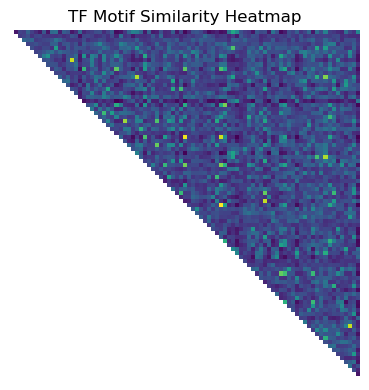

In [ ]:
motif_similarity_matrix = all_pairs_pwm_similarity(tf_random_binding_df.tf_motif.dropna())

tf_similarity_fig = plot_similarity_heatmap(
    motif_similarity_matrix, 
    mask_lower_triangle=True, 
    title="TF Motif Similarity Heatmap"
    )

tf_similarity_fig.show()

In [341]:
top_5_tfs_random_binding = tf_random_binding_df.sort_values(by="binding_mean", ascending=False).head(5)
bottom_5_tfs_random_binding = tf_random_binding_df.sort_values(by="binding_mean", ascending=True).head(5)

print("\n\n--- Top 5 TFs with Highest Mean Binding Probabilities to Random Background DNA Sequences ---")
display(top_5_tfs_random_binding)

print("\n\n--- Bottom 5 TFs with Lowest Mean Binding Probabilities to Random Background DNA Sequences ---")
display(bottom_5_tfs_random_binding)



--- Top 5 TFs with Highest Mean Binding Probabilities to Random Background DNA Sequences ---


,TF_idx,TF_name,binding_mean,binding_std,num_sequences,tf_motif,num_tf_edges,num_true_edges,num_false_edges
30,316,Mbd2,0.850600,0.208750,100,"{'pwm': [[0.07142857142857141, 0.4821428571428...",20894,10447,10447
54,196,E2f1,0.637463,0.208259,100,"{'pwm': [[0.17, 0.024, 0.644, 0.162], [0.058, ...",25116,12558,12558
38,284,Crx,0.629258,0.280147,100,"{'pwm': [[0.010154627279021495, 0.005308100623...",40000,20000,20000
33,290,Duxbl1,0.626390,0.316065,100,"{'pwm': [[0.10391379522051705, 0.4703897766588...",40000,20000,20000
62,181,Mbd1,0.621429,0.239380,100,None,4012,2006,2006




--- Bottom 5 TFs with Lowest Mean Binding Probabilities to Random Background DNA Sequences ---


,TF_idx,TF_name,binding_mean,binding_std,num_sequences,tf_motif,num_tf_edges,num_true_edges,num_false_edges
78,206,Ehf,0.021548,0.054322,100,"{'pwm': [[0.844, 0.006, 0.008, 0.142], [0.142,...",17614,8807,8807
42,16,Hes1,0.033861,0.104306,100,"{'pwm': [[0.04019272553668371, 0.8745294951722...",17072,8536,8536
87,275,Six4,0.082443,0.093801,100,"{'pwm': [[0.9468655325099045, 0.02307154509438...",40000,20000,20000
57,207,Ebf1,0.083019,0.146047,100,"{'pwm': [[0.25, 0.625, 0.125, 0.0], [0.375, 0....",40000,20000,20000
47,149,Hic2,0.091737,0.140152,100,"{'pwm': [[0.07299999999999997, 0.0266666666666...",7236,3618,3618


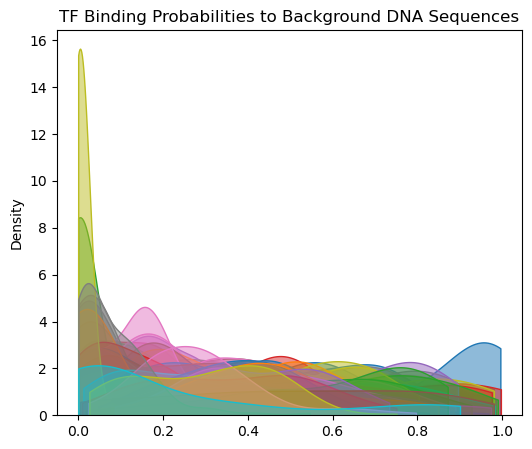

In [340]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(6, 5))
for tf_idx in tf_random_binding_probs.keys():
    probs, _ = tf_random_binding_probs[tf_idx]
    sns.kdeplot(probs, ax=axes, fill=True, cut=0, label=tf_idx_to_name[tf_idx], alpha=0.5)

plt.title("TF Binding Probabilities to Background DNA Sequences")

plt.savefig(PROJECT_DIR / "new_plots" / "tf_dna_binding_evaluation" / "tf_random_dna_binding_kde.png", dpi=300, bbox_inches="tight")

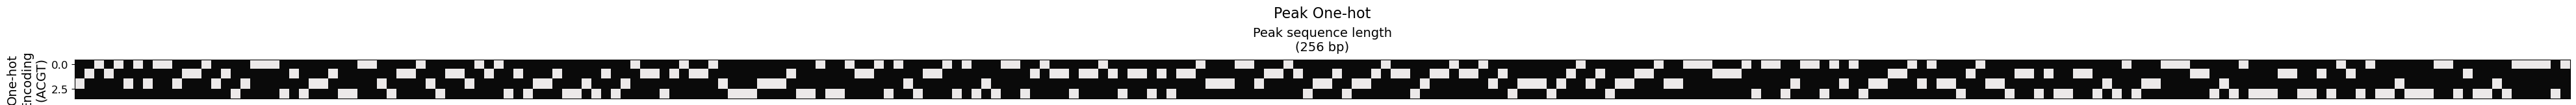

In [88]:
import matplotlib.colors as mcolors

first_peak_onehot = one_hot_peaks[edge_peak_idx_tensor[0]]
peak_dict = {
    "Peak One-hot": (first_peak_onehot, None),
}

colors = ["#0A0A0A", "#ECE9E9"]

# Create a continuous colormap
custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_2_color", colors
)

plot_projected_expression(
    peak_dict, 
    keep_square=False, 
    height=3,
    xlabel=f"Peak sequence length\n({first_peak_onehot.shape[0]} bp)",
    ylabel="One-hot\nEncoding\n(ACGT)",
    cmap=custom_cmap
    )



### TF Dense Layer

In [97]:
tf_embeddings_tensor.device
edge_tf_idx_tensor.device
tf_dna_model.device

device(type='cuda', index=0)

In [98]:
import torch.nn as nn
tf_dna_model.eval()
tf_dna_model.to(device)

tf_input = tf_embeddings_tensor[edge_tf_idx_tensor[0]].unsqueeze(0).to(device=device, dtype=dtype)
m = tf_mask_tensor[edge_tf_idx_tensor[0]].unsqueeze(0).to(device=device, dtype=torch.bool)

tf_encoder_linear1 = tf_dna_model.model.tf_encoder[0](tf_input)
tf_encoder_gelu = tf_dna_model.model.tf_encoder[1](tf_encoder_linear1)
tf_encoder_dropout = tf_dna_model.model.tf_encoder[2](tf_encoder_gelu)
tf_encoder_linear2 = tf_dna_model.model.tf_encoder[3](tf_encoder_dropout)

tf_encoder_output_dict = {
    "TF embedding input": (detach(unmask(tf_input, m)), None),
    "Linear1 Output": (detach(unmask(tf_encoder_linear1, m)), None),
    "GELU Output": (detach(unmask(tf_encoder_gelu, m)), None),
    "Dropout Output": (detach(unmask(tf_encoder_dropout, m)), None),
    "Linear2 Output": (detach(unmask(tf_encoder_linear2, m)), None),
}
    
for key, (values, _) in tf_encoder_output_dict.items():
    print(f"{key}: shape {values.shape}")

TF embedding input: shape (316, 128)
Linear1 Output: shape (316, 128)
GELU Output: shape (316, 128)
Dropout Output: shape (316, 128)
Linear2 Output: shape (316, 128)


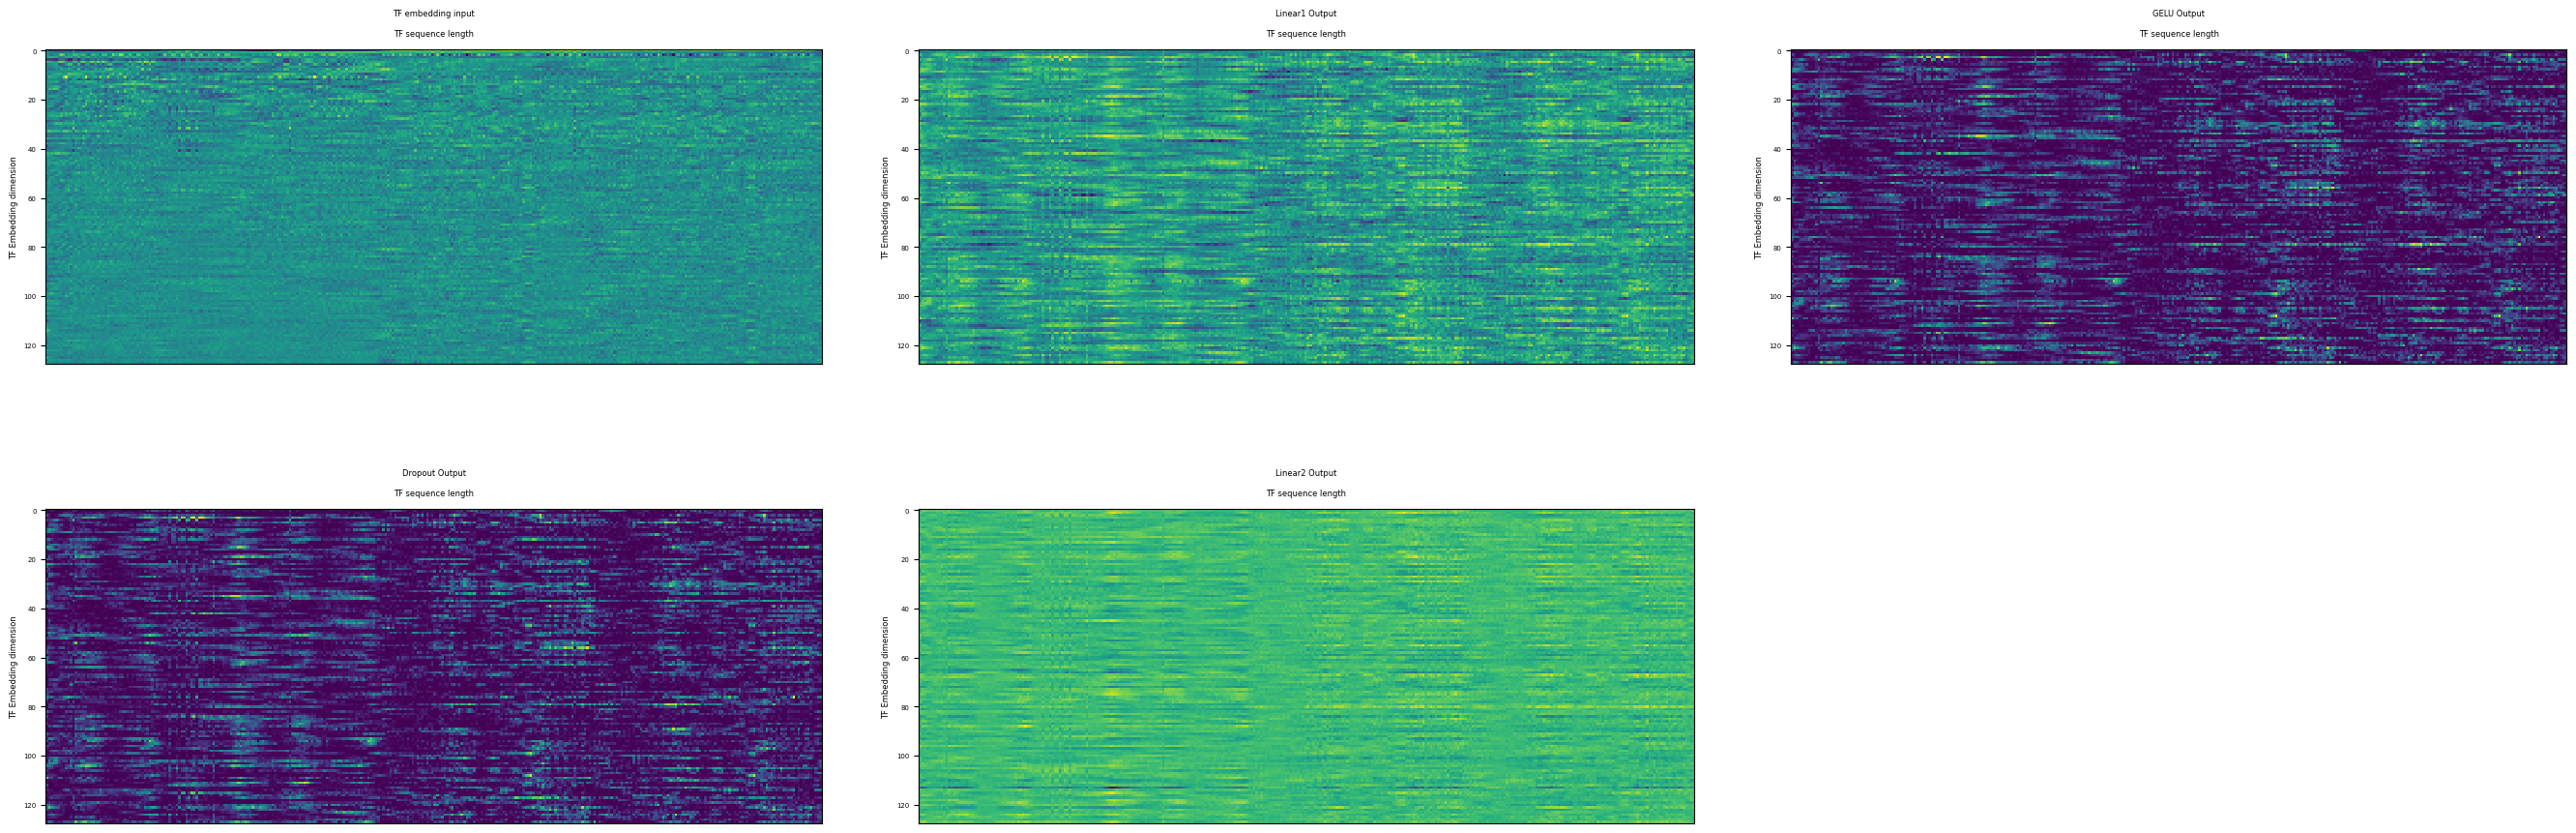

In [99]:
plot_projected_expression(
    tf_encoder_output_dict,
    keep_square=False,
    height=10,
    xlabel="TF sequence length",
    ylabel="TF Embedding dimension"
)

### Peak Encoder

In [100]:
peak_input = one_hot_peaks[edge_peak_idx_tensor[0]].unsqueeze(0).swapaxes(1, 2)
peak_input.to(dtype=torch.float32)
peak_input.shape

torch.Size([1, 4, 256])

Get the activations and weights of the first peak encoder Conv1d

In [116]:
with torch.no_grad():
    activations = tf_dna_model.model.peak_encoder[0](peak_input).permute(1,0,2).cpu().numpy()
    
weights = tf_dna_model.model.peak_encoder[0].weight.detach().cpu().numpy()

print(f"Activation tensor:", activations.shape, activations.dtype)
print(f"Conv2d kernel weights:", weights.shape)

Activation tensor: (64, 1, 256) float32
Conv2d kernel weights: (64, 4, 15)


Plot the activations for each kernel. Each channel is one kernel's activation at each 15bp sliding window position along the 256-bp sequence

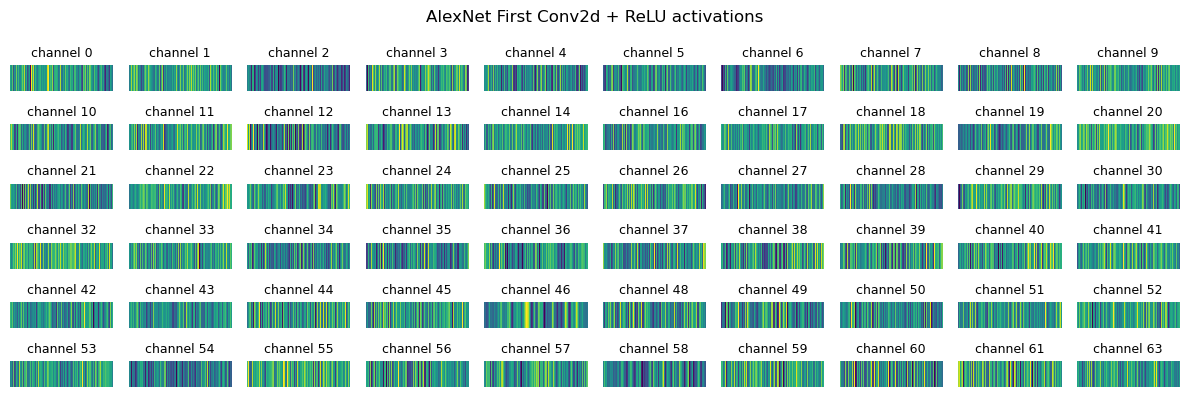

In [ ]:
nrows=6
ncols=10

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4))
axes = axes.flatten()

channels = np.linspace(0, activations.shape[0]-1, num=(nrows*ncols), dtype=np.int16)
for ax, ch in zip(axes, channels):
    sns.heatmap(activations[ch], cmap='viridis', ax=ax, cbar=False)
    ax.set_title(f'channel {ch}', fontsize=9)
    ax.axis('off')
    
# Turn off unused axes
for ax in axes[len(channels):]:
    ax.axis('off')
    
fig.suptitle(f'First Conv1d Layer Activations')
plt.tight_layout()
plt.show()

First Kernel weights

In [124]:
weights.shape

(64, 4, 15)

In [ ]:
def plot_channel_activations(activations, channel):
    fig, ax = plt.subplots(figsize=(10, 0.5))
    sns.heatmap(activations[channel], cmap='viridis', ax=ax, cbar=False)
    ax.set_title(f'Channel {channel}', fontsize=14)
    ax.axis('off')
    plt.show()

def plot_kernel_weights(weights, channel):
    limit = np.abs(weights).max()

    fig, ax = plt.subplots(figsize=(6, 1.8))
    sns.heatmap(
        weights[channel], cmap="coolwarm", vmin=-limit, vmax=limit,
        yticklabels=list("ACGT"), xticklabels=range(1, weights.shape[2] + 1), ax=ax,
        cbar=False
    )
    ax.set_xlabel("Kernel position")
    ax.set_title(f"Kernel weights for output channel {channel}")
    plt.tight_layout()
    plt.show()


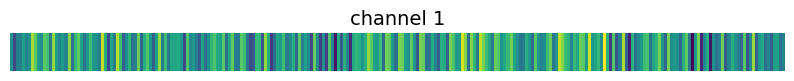

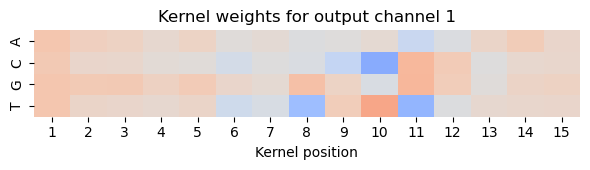

In [155]:
channel = 1
plot_channel_activations(activations, channel)
plot_kernel_weights(weights, channel)

In [224]:
activations.squeeze(1).shape

(64, 256)

In [246]:
# Features = 0, sequence position = 1
i = 12
activation_dims = activations.squeeze(1)[:, i:]
activation_mask = np.ones(activations.squeeze(1).shape, dtype=bool)
activation_mask[:, i:] = False
activation_mask

array([[ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False]], shape=(64, 256))

In [260]:
activations[i].shape

(1, 256)

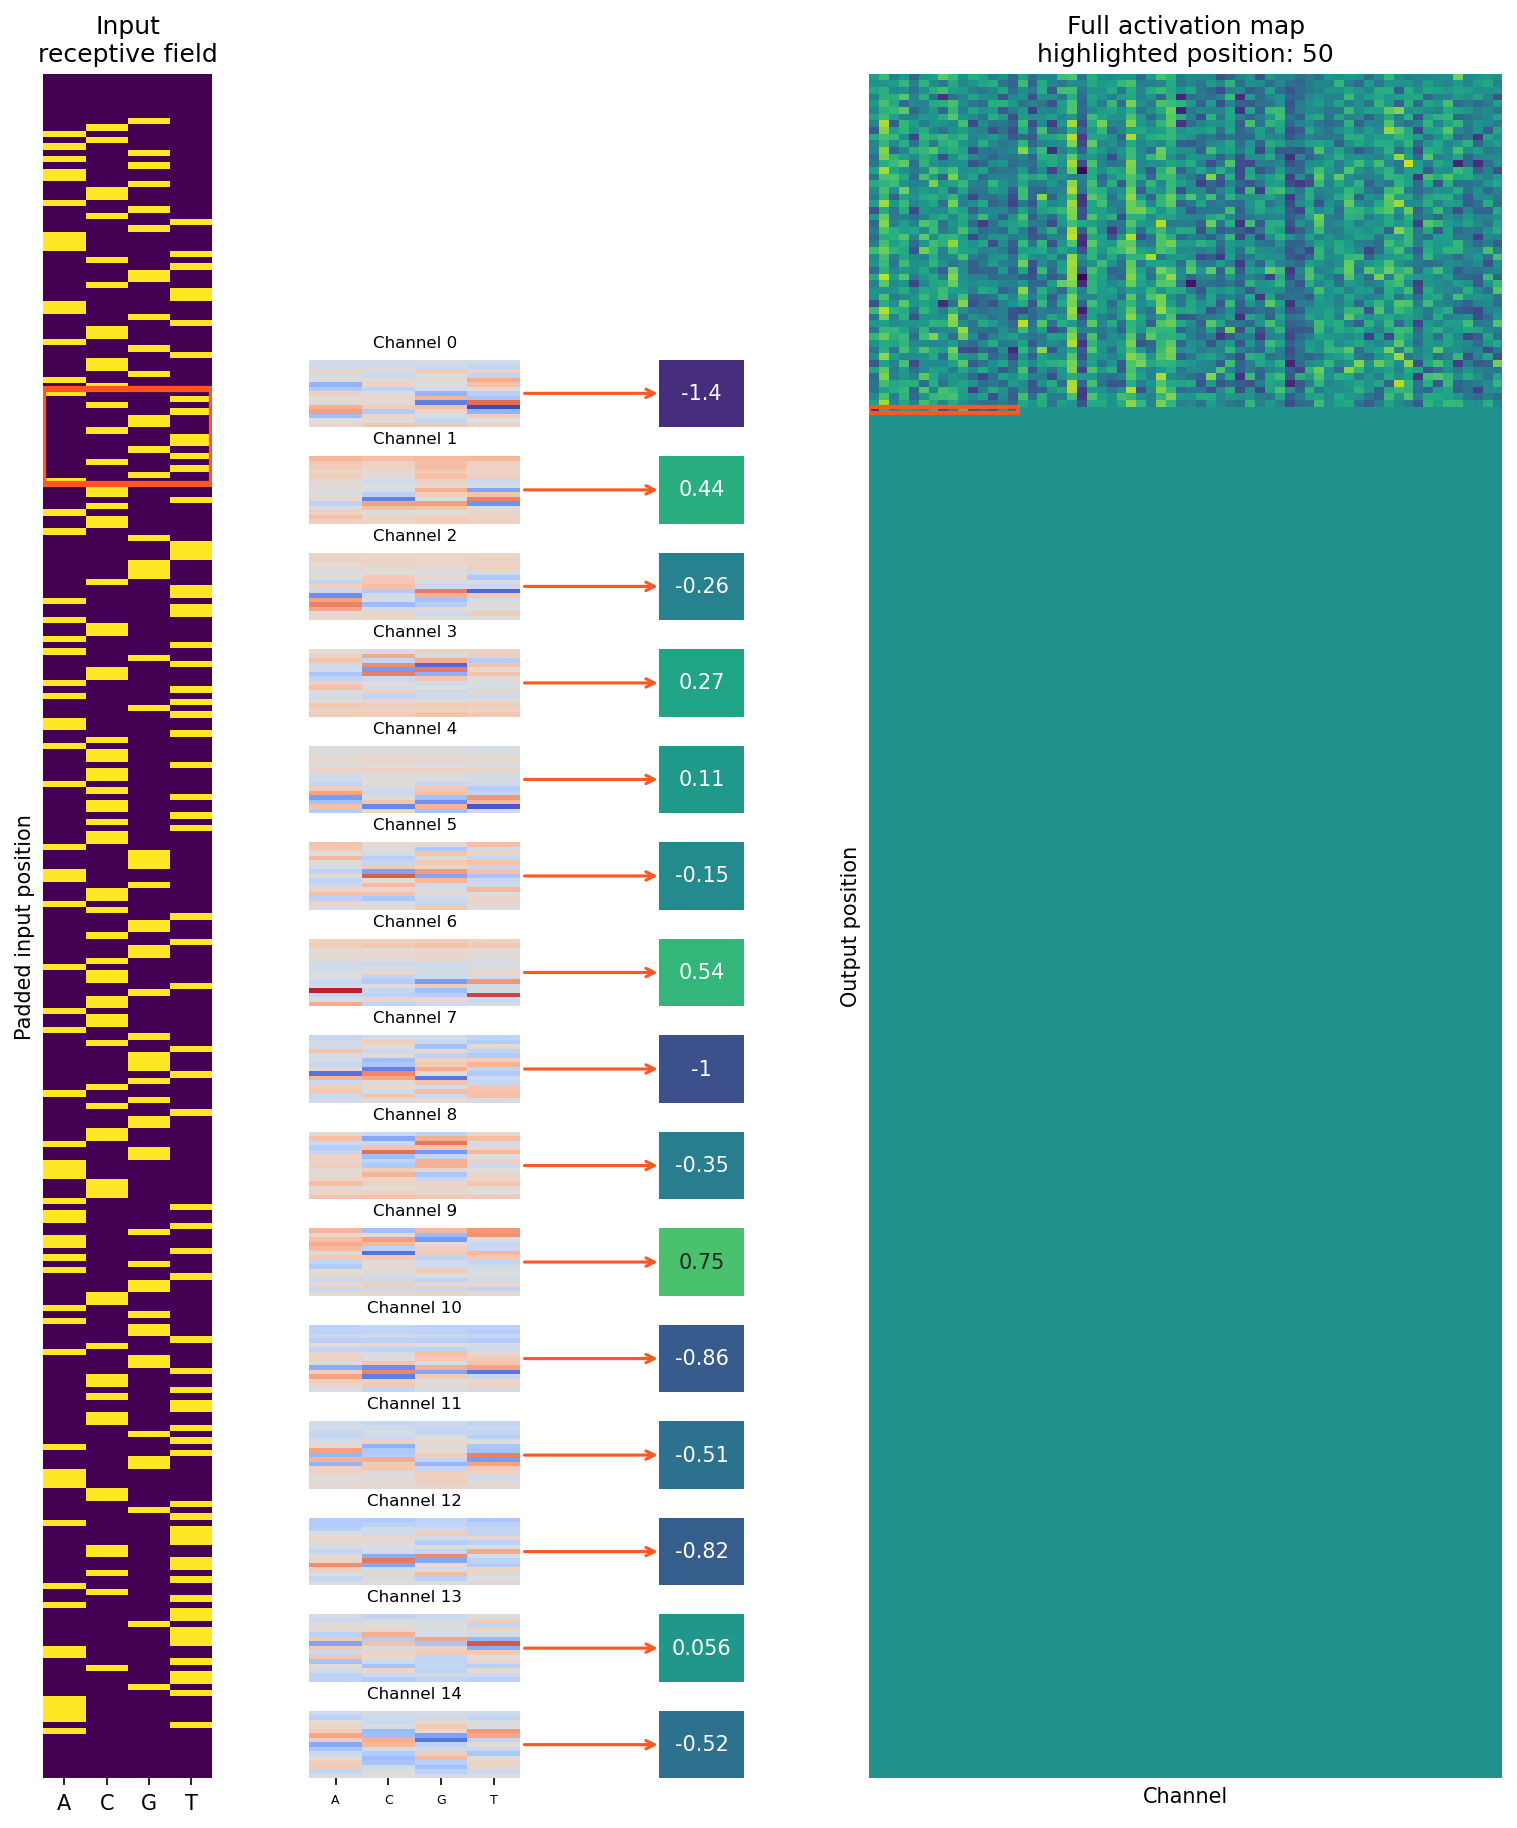

In [328]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns


def plot_activation_receptive_field(
    activations,
    weights,
    i,
    peak_num,
    padding=7,
    stride=1,
    channels=None,
):
    def to_numpy(x):
        return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)

    activations = to_numpy(activations)
    weights = to_numpy(weights)

    if activations.ndim == 3 and activations.shape[1] == 1:
        activations = activations[:, 0, :]

    if activations.ndim != 2:
        raise ValueError("Expected activations shaped (channels, positions).")

    # Default: show several kernels, including the selected channel.
    if channels is None:
        channels = list(dict.fromkeys([0, 1, 2, 3, 4, 5, 6]))
    else:
        channels = list(dict.fromkeys(channels))

    if not channels:
        raise ValueError("Select at least one channel.")

    kernel_size = weights.shape[-1]
    sequence = to_numpy(one_hot_peaks[edge_peak_idx_tensor[peak_num]])
    padded_sequence = np.pad(sequence, ((padding, padding), (0, 0)))
    receptive_start = i * stride

    # One kernel and one activation per row.
    initial_rows = [
        ["input", ".", ".", ".", ".", ".", "full"],
        ["input", ".", ".", ".", ".", ".", "full"],
        ["input", ".", ".", ".", ".", ".", "full"]
    ]
    
    layout = initial_rows + [
        ["input", ".", f"kernel_{ch}", ".", f"value_{ch}", ".", "full"]
        for ch in channels
    ]
    

    fig, axes = plt.subplot_mosaic(
        layout,
        figsize=(10, max(5, 0.8 * len(channels))),
        gridspec_kw={"width_ratios": [
            0.4, # One-hot
            0.2, # Spacer
            0.5, # Kernel
            0.3, # Spacer
            0.2, # Activation
            0.2, # Spacer
            1.5, # Full activation map
            ]},
        constrained_layout=True,
        dpi=150,
    )

    # Input shared by all displayed kernels.
    sns.heatmap(
        padded_sequence,
        cmap="viridis",
        ax=axes["input"],
        cbar=False,
        xticklabels=list("ACGT"),
        yticklabels=False,
    )
    axes["input"].add_patch(
        patches.Rectangle(
            xy=(0, receptive_start),
            width=4,
            height=kernel_size,
            edgecolor="#FF5722",
            facecolor="none",
            linewidth=3,
        )
    )
    axes["input"].set_title("Input\nreceptive field")
    axes["input"].set_ylabel("Padded input position")

    # Shared scales allow comparisons across channels.
    weight_limit = max(float(np.abs(weights[channels]).max()), 1e-12)
    vmin = float(activations.min())
    vmax = float(activations.max())
    if vmin == vmax:
        vmax = vmin + 1e-12

    for ch in channels:
        kernel_ax = axes[f"kernel_{ch}"]
        value_ax = axes[f"value_{ch}"]

        sns.heatmap(
            weights[ch].T,
            cmap="coolwarm",
            vmin=-weight_limit,
            vmax=weight_limit,
            xticklabels=list("ACGT"),
            yticklabels=False,
            ax=kernel_ax,
            cbar=False,
        )
        kernel_ax.set_title(f"Channel {ch}", fontsize=8)
        kernel_ax.set_ylabel("")
        kernel_ax.tick_params(axis="x", labelsize=6)
        
        if ch != channels[-1]:
            kernel_ax.tick_params(
                axis="x", bottom=False, labelbottom=False
            )

        sns.heatmap(
            activations[ch, i].reshape(1, 1),
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            annot=True,
            fmt=".2g",
            xticklabels=False,
            yticklabels=False,
            ax=value_ax,
            cbar=False,
            annot_kws={"fontsize": 10}
        )

        # Connect each kernel to its resulting activation.
        arrow = patches.ConnectionPatch(
            xyA=(1.02, 0.5),
            coordsA=kernel_ax.transAxes,
            xyB=(-0.02, 0.5),
            coordsB=value_ax.transAxes,
            arrowstyle="->",
            color="#FF5722",
            linewidth=1.5,
        )
        fig.add_artist(arrow)
        
        # arrow = patches.ConnectionPatch(
        #     xyA=(1.02, 0.5),
        #     coordsA=value_ax.transAxes,
        #     xyB=(ch + 0.5, i + 0.5),
        #     coordsB=axes["full"].transData,
        #     arrowstyle="->",
        #     color="#FF5722",
        #     linewidth=0.5,
        #     shrinkB=2,
        #     clip_on=False,
        # )
        # fig.add_artist(arrow)

    # All resulting activations.
    activations_masked = np.zeros_like(activations)

    activations_masked[:, :i] = activations[:, :i]
    activations_masked[:channels[-1] + 1, i] = activations[:channels[-1] + 1, i]

    sns.heatmap(
        activations_masked.T,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        ax=axes["full"],
        xticklabels=False,
        yticklabels=False,
        cbar=False,
    )

    
    axes["full"].add_patch(
        patches.Rectangle(
            xy=(channels[0], i),
            width=len(channels),
            height=1,
            edgecolor="#FF5722",
            facecolor="none",
            linewidth=2,
        )
    )

    axes["full"].set_title(f"Full activation map\nhighlighted position: {i}")
    axes["full"].set_xlabel("Channel")
    axes["full"].set_ylabel("Output position")

    
    fig.get_layout_engine().set(
        hspace=0.005,  # Relative spacing between rows
        h_pad=0.005,   # Minimum vertical padding in inches
    )
    
    plt.show()


plot_activation_receptive_field(
    activations,
    weights,
    i=50,
    peak_num=0,
    channels=[i for i in range(15)],
    padding=7,
    stride=1,
)

Maybe for each channel, I can see which DNA sequences activates the channel the most? That way I could figure out if the model responds to certain motifs more strongly overall 

In [101]:
layer = tf_dna_model.model.peak_encoder[0]

peak_input = peak_input.to(
    dtype=layer.weight.dtype,
    device=layer.weight.device,
)

peak_layer_dict = {"Peak Input": (peak_input.squeeze(0), None)}
peak_encoder_output = None
for i in range(len(tf_dna_model.model.peak_encoder)):
    layer = tf_dna_model.model.peak_encoder[i]
    
    if i == 0:
        input = peak_input
    else:
        previous_layer_output = peak_layer_dict[f"{layer_type}_{i-1}"][0]
        input = previous_layer_output
        
    layer_output = layer(input)
    layer_type = layer.__class__.__name__
    
    peak_layer_dict[f"{layer_type}_{i}"] = (layer_output, None)
    
    print(f"{layer_type}_{i}")
    print(f"  input shape: {input.shape}")
    print(f"  output shape: {layer_output.shape}")
    
    if i == len(tf_dna_model.model.peak_encoder) - 1:
        peak_encoder_output = layer_output
    
# Detach all tensors in peak_layer_dict
for key in peak_layer_dict:
    peak_layer_dict[key] = (detach(peak_layer_dict[key][0]), peak_layer_dict[key][1])


Conv1d_0
  input shape: torch.Size([1, 4, 256])
  output shape: torch.Size([1, 64, 256])
BatchNorm1d_1
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 256])
GELU_2
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 256])
MaxPool1d_3
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 64])
Conv1d_4
  input shape: torch.Size([1, 64, 64])
  output shape: torch.Size([1, 128, 64])
BatchNorm1d_5
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 64])
GELU_6
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 64])
MaxPool1d_7
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 16])
Conv1d_8
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16])
BatchNorm1d_9
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16])
GELU_10
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16

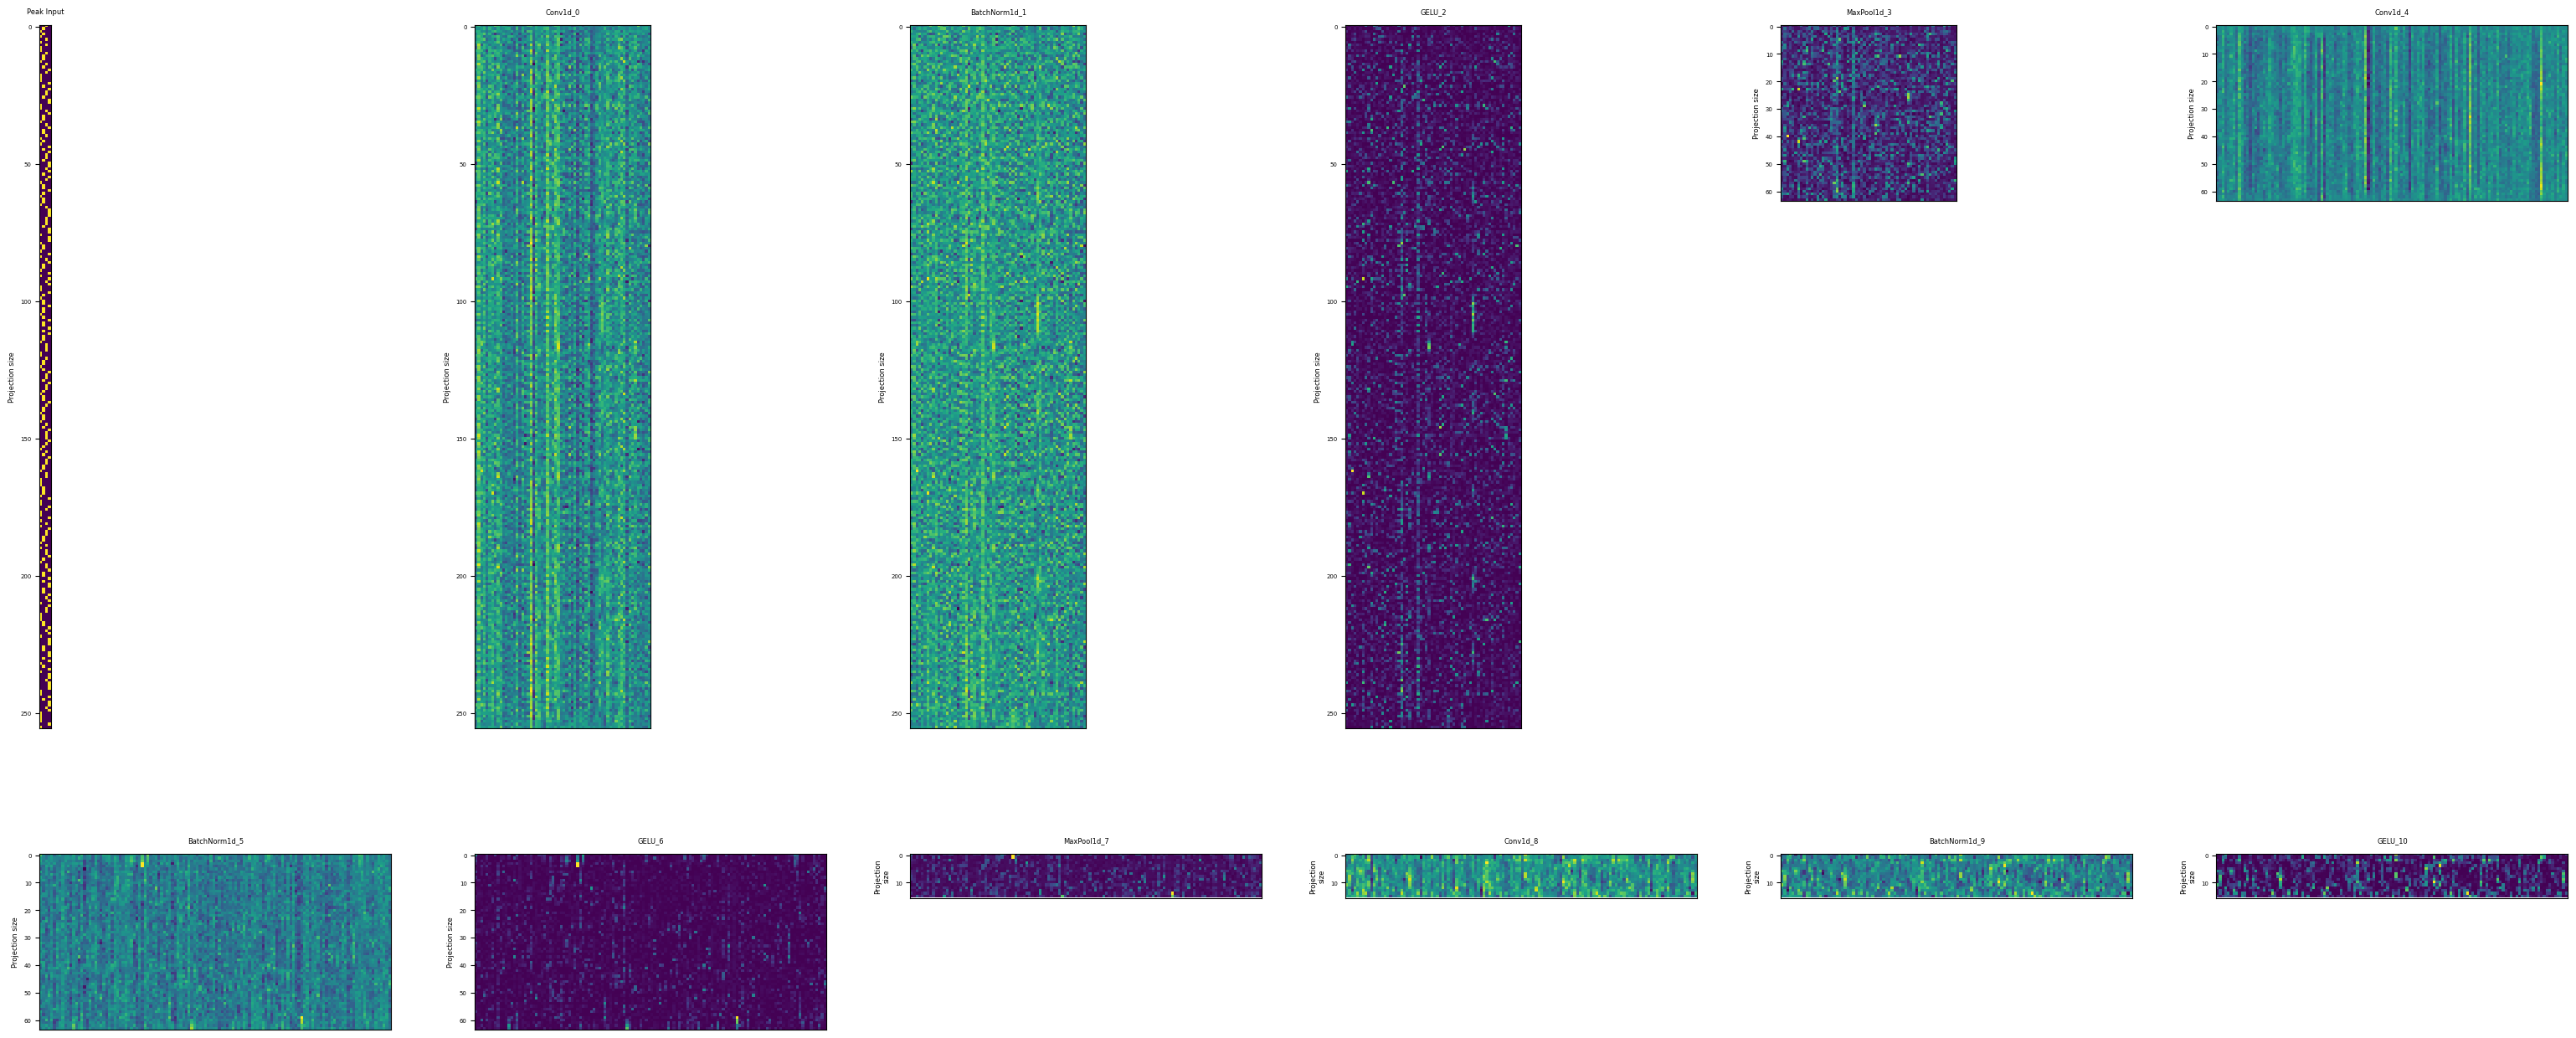

In [102]:
plot_projected_expression(
    peak_layer_dict,
    keep_square=False,
    height=14,
    ncols=6
)

### Cross Attention

In [21]:
tf_cross_input = tf_encoder_linear2
peak_cross_input = peak_encoder_output.transpose(1, 2)

peak_mask = torch.ones(
    peak_cross_input.shape[:2],
    dtype=torch.bool,
    device=peak_cross_input.device,
)

In [22]:
tf_dna_model.model.cross_attn.layers[0][1][0]

RMSNorm((128,), eps=None, elementwise_affine=True)

In [23]:
import torch

cross_attn = tf_dna_model.model.cross_attn
cross_layer_dict = {}
handles = []

def snapshot(output):
    """Store detached copies, preserving tuples/lists/dictionaries."""
    if isinstance(output, torch.Tensor):
        return output.detach().clone()
    if isinstance(output, tuple):
        return tuple(snapshot(value) for value in output)
    if isinstance(output, list):
        return [snapshot(value) for value in output]
    if isinstance(output, dict):
        return {key: snapshot(value) for key, value in output.items()}
    return output


def make_hook(name):
    def hook(module, inputs, output):
        cross_layer_dict[name] = snapshot(output)
    return hook


# Register hooks on each layer and all modules inside it.
for layer_num, layer in enumerate(cross_attn.layers):
    for module_name, module in layer.named_modules():
        name = f"CrossAttention_{layer_num}"
        if module_name:
            name += f"_{module_name.replace('.', '_')}"

        handles.append(
            module.register_forward_hook(make_hook(name))
        )

try:
    with torch.no_grad():
        # Use the same forward call and arguments as your normal execution.
        output = cross_attn(
            tf_cross_input,
            peak_cross_input,
            m,
            peak_mask,
        )
finally:
    # Remove hooks even if the forward pass raises an error.
    for handle in handles:
        handle.remove()

In [24]:
for name, output in cross_layer_dict.items():
    if isinstance(output, torch.Tensor):
        print(f"{name}: {output.shape}")
    elif isinstance(output, tuple):
        print(f"{name}: {[o.shape if isinstance(o, torch.Tensor) else type(o) for o in output]}")
    else:
        print(f"{name}: {type(output)}")

CrossAttention_0_0_norm: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_norm: torch.Size([1, 16, 128])
CrossAttention_0_0_to_qk: torch.Size([1, 5588, 128])
CrossAttention_0_0_to_v: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_to_qk: torch.Size([1, 16, 128])
CrossAttention_0_0_context_to_v: torch.Size([1, 16, 128])
CrossAttention_0_0_dropout: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_context_dropout: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_talking_heads: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_context_talking_heads: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_to_out: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_to_out: torch.Size([1, 16, 128])
CrossAttention_0_0: [torch.Size([1, 5588, 128]), torch.Size([1, 16, 128])]
CrossAttention_0_1_0: torch.Size([1, 5588, 128])
CrossAttention_0_1_1: torch.Size([1, 5588, 512])
CrossAttention_0_1_2: torch.Size([1, 5588, 512])
CrossAttention_0_1_3: torch.Size([1, 5588, 128])
CrossAttention_0_1: torch.S

In [25]:
def make_cross_attention_heatmaps(
    outputs,
    tf_mask,
    peak_mask,
    batch_index=0,
):
    heatmaps = {}

    # Select masks for one batch item.
    tf_valid = tf_mask[batch_index].detach().cpu().bool()
    peak_valid = peak_mask[batch_index].detach().cpu().bool()

    def add_output(name, output):
        # Handle modules returning multiple outputs.
        if isinstance(output, (tuple, list)):
            for index, value in enumerate(output):
                add_output(f"{name}_output_{index}", value)
            return

        if not isinstance(output, torch.Tensor):
            return

        tensor = output.detach().float().cpu()

        # Token features: (batch, tokens, features)
        if tensor.ndim == 3:
            matrix = tensor[batch_index]

            # Infer the token type from its length.
            # This works for your distinct TF/peak lengths: 5588 and 16.
            if matrix.shape[0] == len(tf_valid):
                matrix = matrix[tf_valid]
            elif matrix.shape[0] == len(peak_valid):
                matrix = matrix[peak_valid]
            else:
                raise ValueError(
                    f"{name}: cannot identify token dimension "
                    f"for shape {tuple(tensor.shape)}"
                )

            if matrix.shape[0] > 0:
                heatmaps[name] = (matrix.numpy(), None)

        # Attention: (batch, heads, TF tokens, peak tokens)
        elif tensor.ndim == 4:
            if tensor.shape[2:] != (len(tf_valid), len(peak_valid)):
                raise ValueError(
                    f"{name}: unexpected attention shape "
                    f"{tuple(tensor.shape)}"
                )

            attention = tensor[batch_index]
            attention = attention[:, tf_valid, :]
            attention = attention[:, :, peak_valid]

            for head_index, matrix in enumerate(attention):
                if all(size > 0 for size in matrix.shape):
                    heatmaps[f"{name}_head_{head_index}"] = (
                        matrix.numpy(),
                        None,
                    )

    for name, output in outputs.items():
        add_output(name, output)

    return heatmaps

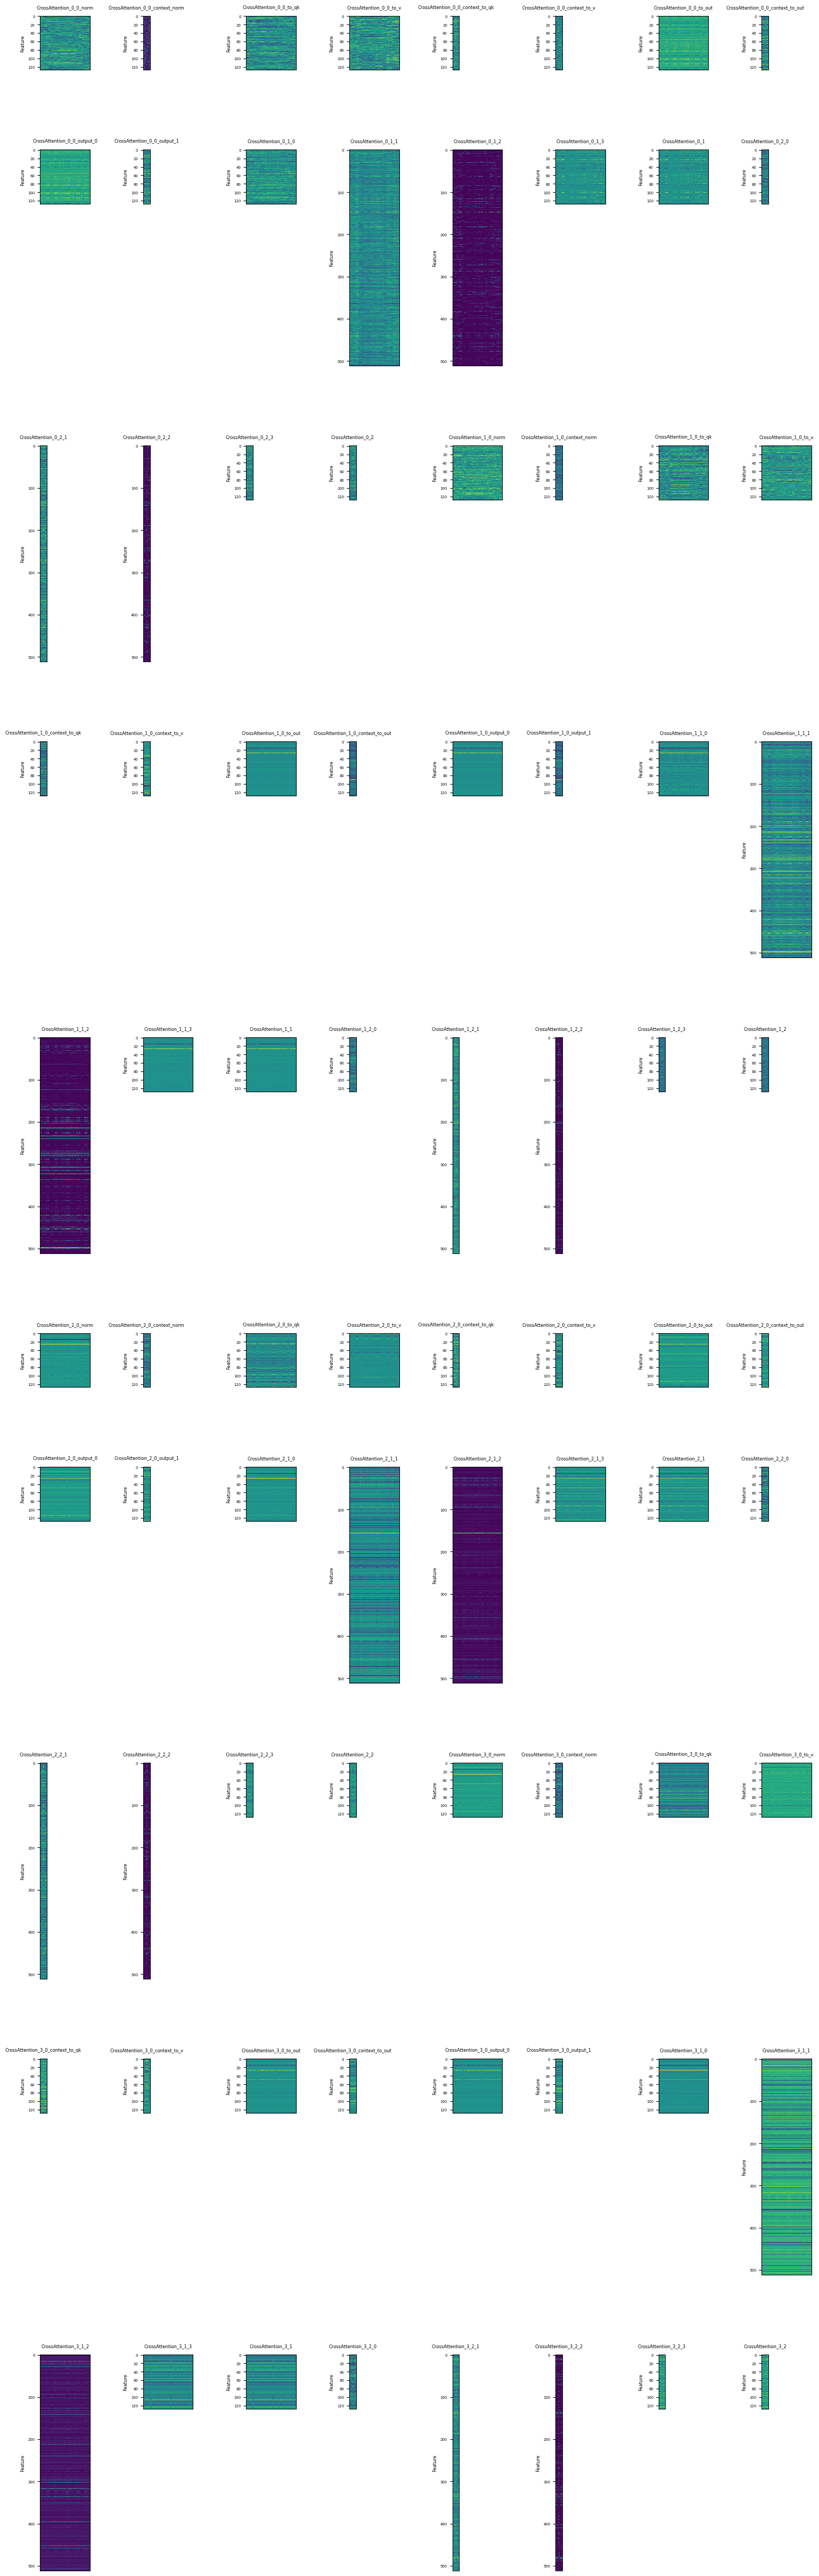

In [26]:
selected = {
    name: output
    for name, output in cross_layer_dict.items()
    if name.startswith("CrossAttention_")
}

heatmaps = make_cross_attention_heatmaps(
    selected,
    tf_mask=m,
    peak_mask=peak_mask,
)

# Plot feature outputs separately from attention matrices.
feature_heatmaps = {
    name: value
    for name, value in heatmaps.items()
    if "_head_" not in name
}

plot_projected_expression(
    feature_heatmaps,
    ncols=8,
    height=50,
    xlabel=None,
    ylabel="Feature",
)

### Full Model Flow

In [35]:
STREAM_COLORS = {
    "TF": "#1f77b4",
    "Peak": "#d62728",
    "Attention": "#9467bd",
    "Joint": "#444444",
}


def describe_module(module):
    """Short module name with its weight shape, e.g. 'Linear 128→512'."""
    name = type(module).__name__
    if isinstance(module, nn.Linear):
        return f"{name} {module.in_features}→{module.out_features}"
    if isinstance(module, nn.Conv1d):
        return f"{name} {module.in_channels}→{module.out_channels}, k={module.kernel_size[0]}"
    return name


def capture_model_flow(model, tf_embedding, tf_mask, peak_embedding):
    """
    Run one forward pass and record each intermediate output in execution order.

    tf_embedding:   [1, tf_len, 128]
    tf_mask:        [1, tf_len], True for real TF tokens
    peak_embedding: [1, 256, 4] one-hot DNA

    Returns a list of dicts with keys:
        label:  "<block> · <stage>"
        stream: "TF", "Peak", "Attention", or "Joint"
        matrix: 2D array, rows = features, columns = positions
        groups: number of attention heads stacked in the rows, else None

    Forward hooks fire in the order the modules run, so the list follows the
    real forward pass. The residual sums between blocks are not modules, so
    they are rebuilt from each block's input and output.

    The model runs in eval mode, so Dropout is the identity and BatchNorm uses
    its running statistics. Dropout layers are therefore not recorded, except
    the two in the attention block, whose outputs are the attention weights.
    """
    net = getattr(model, "model", model)
    device = next(net.parameters()).device

    tf_embedding = tf_embedding.to(device=device, dtype=torch.float32)
    tf_mask = tf_mask.to(device).bool()
    peak_embedding = peak_embedding.to(device=device, dtype=torch.float32)

    tf_valid = tf_mask[0].cpu()
    records = []
    handles = []

    def to_matrix(tensor, stream, layout):
        values = tensor.detach().float().cpu()[0]

        if layout == "tokens":
            # [tokens, features] -> [features, tokens], without TF padding
            if stream == "TF":
                values = values[tf_valid]
            values = values.T
        elif layout == "attention":
            # [heads, TF tokens, peak tokens] -> [heads * peak tokens, TF tokens]
            values = values[:, tf_valid, :].transpose(1, 2)
            values = values.reshape(-1, values.shape[-1])
        elif layout == "vector":
            values = values.reshape(1, -1)
        # The "channels" layout is already [channels, positions]

        return values.numpy()

    def add(label, stream, layout, tensor, groups=None):
        records.append({
            "label": label,
            "stream": stream,
            "matrix": to_matrix(tensor, stream, layout),
            "groups": groups,
        })

    def watch_output(module, label, stream, layout, groups=None):
        def hook(module, inputs, output):
            add(label, stream, layout, output, groups)
        handles.append(module.register_forward_hook(hook))

    def watch_input(module, label, stream, layout):
        def hook(module, inputs):
            add(label, stream, layout, inputs[0])
        handles.append(module.register_forward_pre_hook(hook))

    # Encoders
    watch_input(net.tf_encoder[0], "TF embedding input", "TF", "tokens")
    for module in net.tf_encoder:
        if not isinstance(module, nn.Dropout):
            watch_output(module, f"TF encoder · {describe_module(module)}", "TF", "tokens")

    watch_input(net.peak_encoder[0], "Peak one-hot input", "Peak", "channels")
    for module in net.peak_encoder:
        watch_output(module, f"Peak encoder · {describe_module(module)}", "Peak", "channels")

    # Cross-attention layers
    for layer_num, (attn, ff, context_ff) in enumerate(net.cross_attn.layers):
        block = f"Cross-attn {layer_num}"

        for module, name, stream in [
            (attn.norm, "RMSNorm", "TF"),
            (attn.context_norm, "RMSNorm", "Peak"),
            (attn.to_qk, "query/key", "TF"),
            (attn.to_v, "value", "TF"),
            (attn.context_to_qk, "query/key", "Peak"),
            (attn.context_to_v, "value", "Peak"),
        ]:
            watch_output(module, f"{block} · {stream} {name}", stream, "tokens")

        # Each TF token's weights over peak tokens (columns sum to 1 per head),
        # then each peak token's weights over TF tokens (rows sum to 1).
        watch_output(attn.dropout, f"{block} · TF reads peak", "Attention", "attention", attn.heads)
        watch_output(attn.context_dropout, f"{block} · Peak reads TF", "Attention", "attention", attn.heads)

        watch_output(attn.to_out, f"{block} · TF attention output", "TF", "tokens")
        watch_output(attn.context_to_out, f"{block} · Peak attention output", "Peak", "tokens")

        def attention_residual_hook(module, inputs, output, block=block):
            (x, context), (x_out, context_out) = inputs, output
            add(f"{block} · TF residual + attention", "TF", "tokens", x + x_out)
            add(f"{block} · Peak residual + attention", "Peak", "tokens", context + context_out)
        handles.append(attn.register_forward_hook(attention_residual_hook))

        for stream, feedforward in (("TF", ff), ("Peak", context_ff)):
            for module in feedforward:
                watch_output(module, f"{block} · {stream} FF {describe_module(module)}", stream, "tokens")

            def ff_residual_hook(module, inputs, output, block=block, stream=stream):
                add(f"{block} · {stream} residual + FF", stream, "tokens", inputs[0] + output)
            handles.append(feedforward.register_forward_hook(ff_residual_hook))

    watch_output(net.cross_attn.norm, "Final RMSNorm · TF", "TF", "tokens")
    watch_output(net.cross_attn.context_norm, "Final RMSNorm · Peak", "Peak", "tokens")

    # The classifier input is [TF mean pool, peak mean pool]
    def pooled_hook(module, inputs):
        tf_pooled, peak_pooled = inputs[0].chunk(2, dim=-1)
        add("Mean pool · TF", "TF", "vector", tf_pooled)
        add("Mean pool · Peak", "Peak", "vector", peak_pooled)
    handles.append(net.classifier[0].register_forward_pre_hook(pooled_hook))

    for module in net.classifier:
        if not isinstance(module, nn.Dropout):
            watch_output(module, f"Classifier · {describe_module(module)}", "Joint", "vector")

    was_training = net.training
    net.eval()
    try:
        with torch.no_grad():
            net(tf_embedding, tf_mask, peak_embedding)
    finally:
        # Remove hooks and restore the mode even if the forward pass fails.
        for handle in handles:
            handle.remove()
        net.train(was_training)

    return records


def color_range(matrix, robust):
    """Color scale limits for one heatmap: the 2nd-98th percentiles if robust, else min-max."""
    if robust:
        low, high = np.percentile(matrix, [2, 98])
    else:
        low, high = matrix.min(), matrix.max()
    if high <= low:
        high = low + 1e-6  # Constant heatmaps, such as the 1 x 1 logit
    return low, high


def block_mean(matrix, max_cells):
    """Average blocks of rows and columns so neither axis exceeds max_cells."""
    # Small planes, such as the one-hot DNA input, keep their exact values
    if not max_cells or matrix.size <= max_cells ** 2:
        return matrix

    for axis in (0, 1):
        n = matrix.shape[axis]
        if max_cells and n > max_cells:
            starts = np.linspace(0, n, max_cells + 1).astype(int)
            counts = np.diff(starts)
            sums = np.add.reduceat(matrix, starts[:-1], axis=axis)
            matrix = sums / (counts[:, None] if axis == 0 else counts[None, :])
    return matrix


# Left and right arrow keys move the slider one step.
SLIDER_ARROW_KEYS_JS = """
var gd = document.getElementById('{plot_id}');
document.addEventListener('keydown', function (event) {
    if (event.key !== 'ArrowLeft' && event.key !== 'ArrowRight') return;
    var slider = gd.layout.sliders[0];
    var next = slider.active + (event.key === 'ArrowRight' ? 1 : -1);
    if (next < 0 || next >= slider.steps.length) return;
    var args = slider.steps[next].args;
    var layoutUpdate = Object.assign({'sliders[0].active': next}, args[1]);
    Plotly.update(gd, args[0], layoutUpdate, args[2]);
});
"""


def plot_model_flow(
    records,
    output_path,
    title=None,
    max_cells=64,
    z_scale=3.0,
    colorscale="Viridis",
    robust=True,
    faded_opacity=0.1,
):
    """
    Stack the heatmaps from capture_model_flow along z in execution order and
    write the figure to a standalone HTML file at output_path.

    Each stage is a flat plane with one unit per element: its x size is the
    number of columns (positions) and its y size is the number of rows
    (features). All planes start at the origin, so the x and y axes read as
    element counts. z is the processing order, with extra space where a new
    block starts. z_scale sets the stack height relative to the largest
    plane side.

    A slider under the plot steps through the stages. At each step, the
    selected stage is opaque, the stages before it have faded_opacity, and
    the stages after it are hidden. The first step, "All", shows the full
    stack. The left and right arrow keys also move the slider.

    Planes with more than max_cells ** 2 elements are block-averaged to at most
    max_cells cells per axis, to keep the file small. Smaller planes, such as
    the one-hot DNA input, are drawn exactly. Every plane keeps its true size.
    None draws every element.

    Each plane has its own color scale. robust=True clips it to the 2nd-98th
    percentiles, so a few large features do not hide the rest.
    Hover shows the stage, its shape, and the cell value. Click a stream in
    the legend to hide or show it. "Stage labels" adds a label to each plane.

    The HTML embeds plotly.js, so it opens without an internet connection.
    Returns output_path.
    """
    if not records:
        raise ValueError("records must not be empty")

    n_stages = len(records)

    # One z level per stage, plus extra space where a new block starts
    blocks = [record["label"].split(" · ")[0] for record in records]
    steps = [0] + [
        1 + (2 if blocks[i] != blocks[i - 1] else 0)
        for i in range(1, n_stages)
    ]
    z_levels = np.cumsum(steps).astype(float)

    max_rows = max(record["matrix"].shape[0] for record in records)
    max_cols = max(record["matrix"].shape[1] for record in records)
    longest = max(max_rows, max_cols)

    # Each stage adds two traces, its plane and its outline, so the slider
    # can fade or hide them together: stage i owns traces 2i and 2i + 1.
    fig = go.Figure()
    in_legend = set()

    for record, z in zip(records, z_levels):
        matrix = record["matrix"]
        rows, cols = matrix.shape
        stream = record["stream"]

        cmin, cmax = color_range(matrix, robust)
        shown = block_mean(matrix, max_cells)

        # Repeat the inner cell edges and the values, so each cell is a flat
        # square of one color instead of a gradient between cell centers.
        x = np.repeat(np.linspace(0, cols, shown.shape[1] + 1), 2)[1:-1]
        y = np.repeat(np.linspace(0, rows, shown.shape[0] + 1), 2)[1:-1]
        color = np.repeat(np.repeat(shown, 2, axis=0), 2, axis=1).astype(np.float32)

        hover = f"<b>{record['label']}</b><br>{rows} × {cols}"
        if shown.shape != matrix.shape:
            hover += f", shown as {shown.shape[0]} × {shown.shape[1]} block means"

        fig.add_trace(go.Surface(
            x=x,
            y=y,
            z=np.full(color.shape, z, dtype=np.float32),
            surfacecolor=color,
            customdata=color,  # Surface hover cannot read surfacecolor
            cmin=cmin,
            cmax=cmax,
            colorscale=colorscale,
            showscale=False,
            # Flat lighting, so the colors are not shaded
            lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0, fresnel=0.0),
            name=record["label"],
            legendgroup=stream,
            hovertemplate=hover + "<br>value %{customdata:.3g}<extra></extra>",
        ))

        # Plane border, plus a line between attention heads
        outline_x = [0, cols, cols, 0, 0]
        outline_y = [0, 0, rows, rows, 0]
        if record["groups"]:
            for boundary in np.arange(1, record["groups"]) * rows / record["groups"]:
                outline_x += [None, 0, cols]
                outline_y += [None, boundary, boundary]

        # The first outline of each stream is its legend entry. Clicking it
        # hides the whole stream, because all its traces share a legend group.
        fig.add_trace(go.Scatter3d(
            x=outline_x,
            y=outline_y,
            z=[None if value is None else z for value in outline_x],
            mode="lines",
            line=dict(color=STREAM_COLORS[stream], width=3),
            name="Classifier" if stream == "Joint" else stream,
            legendgroup=stream,
            showlegend=stream not in in_legend,
            hoverinfo="skip",
        ))
        in_legend.add(stream)

    fig.add_trace(go.Scatter3d(
        x=np.zeros(n_stages),
        y=np.zeros(n_stages),
        z=z_levels,
        mode="text",
        text=[record["label"] for record in records],
        textposition="middle left",
        textfont=dict(
            color=[STREAM_COLORS[record["stream"]] for record in records],
            size=10,
        ),
        name="Stage labels",
        visible="legendonly",  # Readable once zoomed in
        hoverinfo="skip",
    ))

    def slider_step(selected):
        """Show every stage (selected=None), or focus on one stage."""
        opacity, visible, hoverinfo = [], [], []
        for i in range(n_stages):
            if selected is None or i == selected:
                stage_opacity, stage_visible, stage_hover = 1.0, True, "all"
            elif i < selected:
                stage_opacity, stage_visible, stage_hover = faded_opacity, True, "skip"
            else:
                stage_opacity, stage_visible, stage_hover = 1.0, False, "skip"

            # Plane, then outline. Faded planes do not take the hover.
            opacity += [stage_opacity, stage_opacity]
            visible += [stage_visible, stage_visible]
            hoverinfo += [stage_hover, "skip"]

        if selected is None:
            subtitle = f"All {n_stages} stages"
        else:
            rows, cols = records[selected]["matrix"].shape
            subtitle = f"Stage {selected + 1}/{n_stages}: {records[selected]['label']} ({rows} × {cols})"

        return dict(
            method="update",
            label="All" if selected is None else "",
            value="all" if selected is None else str(selected),
            args=[
                {"opacity": opacity, "visible": visible, "hoverinfo": hoverinfo},
                {"title.text": f"{title}<br><sup>{subtitle}</sup>" if title else subtitle},
                list(range(2 * n_stages)),
            ],
        )

    slider_steps = [slider_step(None)] + [slider_step(i) for i in range(n_stages)]

    block_starts = [i for i in range(n_stages) if i == 0 or blocks[i] != blocks[i - 1]]

    fig.update_layout(
        title=slider_steps[0]["args"][1]["title.text"],
        margin=dict(l=0, r=0, t=70, b=70),
        # Keep the camera when the slider changes the traces
        uirevision="model-flow",
        sliders=[dict(
            active=0,
            steps=slider_steps,
            currentvalue=dict(visible=False),  # The title names the stage
            x=0.05,
            len=0.9,
            pad=dict(t=0, b=10),
        )],
        scene=dict(
            xaxis=dict(title="Columns (positions)", range=[0, max_cols]),
            yaxis=dict(title="Rows (features)", range=[0, max_rows]),
            zaxis=dict(
                title="",
                # Fixed range, so hiding later stages does not rescale the plot
                range=[z_levels[0] - 1, z_levels[-1] + 1],
                tickvals=[z_levels[i] for i in block_starts],
                ticktext=[blocks[i] for i in block_starts],
            ),
            aspectmode="manual",
            aspectratio=dict(x=max_cols / longest, y=max_rows / longest, z=z_scale),
            camera=dict(eye=dict(x=1.6, y=-1.6, z=0.6)),
        ),
    )

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.write_html(
        output_path,
        include_plotlyjs=True,
        default_height="100vh",
        post_script=SLIDER_ARROW_KEYS_JS,
    )
    logging.info(f"Saved {output_path} ({output_path.stat().st_size / 1e6:.1f} MB)")

    return output_path


def stage_file_stem(stage_number, label):
    """File name for one stage, e.g. (25, 'Cross-attn 0 · TF attention output')
    -> '025_Cross-attn_0_TF_attention_output'."""
    name = label.replace("→", "to").replace("+", "plus").replace("/", "-").replace("=", "")
    name = re.sub(r"[^A-Za-z0-9-]+", "_", name).strip("_")
    return f"{stage_number:03d}_{name}"


def save_flow_heatmaps(records, output_dir, cell_size=2.0, cmap="viridis", robust=True):
    """
    Save each stage from capture_model_flow as its own SVG heatmap in
    output_dir, with no title, axes, ticks, or colorbar.

    Every element is a cell_size x cell_size point square, so all the images
    share one scale: a 512-feature layer is 4 times taller than a 128-feature
    layer. Every element is drawn; nothing is block-averaged. The SVG embeds
    the matrix at one image pixel per element and tells viewers not to smooth
    it, so the cells stay sharp at any zoom.

    Each heatmap has its own color scale, the same as in plot_model_flow.

    File names start with the 1-based stage number, which is also the stage
    number on the plot_model_flow slider, e.g.
    025_Cross-attn_0_TF_attention_output.svg. Returns output_dir.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    for stage_number, record in enumerate(records, start=1):
        matrix = record["matrix"]
        rows, cols = matrix.shape
        vmin, vmax = color_range(matrix, robust)

        # The axes fill the whole figure, and the figure is cell_size points
        # per element, so the heatmap has no border or padding.
        fig = plt.figure(figsize=(cols * cell_size / 72, rows * cell_size / 72))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.axis("off")
        fig.patch.set_visible(False)  # No background box
        image = ax.imshow(
            matrix,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            aspect="auto",
            interpolation="none",  # Embed the matrix unresampled
        )
        image.set_clip_on(False)  # No clip path around the image

        fig.savefig(output_dir / f"{stage_file_stem(stage_number, record['label'])}.svg")
        plt.close(fig)

    logging.info(f"Saved {len(records)} SVG heatmaps to {output_dir}")

    return output_dir

In [ ]:
dataset_item_num = 4

tf_idx = int(dataset[dataset_item_num]["tf_idx"])
peak_idx = int(dataset[dataset_item_num]["peak_idx"])

tf_embedding = tf_embeddings_tensor[dataset[dataset_item_num]["tf_idx"]].unsqueeze(0).to(device=device, dtype=dtype)
tf_mask = tf_mask_tensor[dataset[dataset_item_num]["tf_idx"]].unsqueeze(0).to(device=device, dtype=torch.bool)
peak_onehot = one_hot_peaks[dataset[dataset_item_num]["peak_idx"]].unsqueeze(0).to(device=device, dtype=dtype)

tf_names = pd.read_csv(tf_dna_input_cache_dir / "tf_name_to_idx.csv").set_index("tf_idx")["tf_name"]
tf_name = tf_names[tf_idx]

flow = capture_model_flow(
    tf_dna_model,
    tf_embedding=tf_embedding,
    tf_mask=tf_mask,
    peak_embedding=peak_onehot,
)

logit = flow[-1]["matrix"].item()
probability = 1 / (1 + np.exp(-logit))

print(f"{len(flow)} stages, logit {logit:.3f}, binding probability {probability:.3f}")

output_path = PROJECT_DIR / "new_plots" / "model_flow" / f"model_flow_{species}_{tf_name}_peak{peak_idx}.html"

plot_model_flow(
    flow,
    output_path=output_path,
    title=f"{tf_name} × peak {peak_idx} ({species}) · logit {logit:.2f}, binding probability {probability:.3f}",
)

# One SVG per stage, in a folder named after the HTML file
save_flow_heatmaps(flow, output_dir=output_path.with_suffix(""))

113 stages, logit 3.076, binding probability 0.956


2026-10-15 10:47:01 - INFO - Saved /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_flow/model_flow_mm10_Cebpb_peak1463383.html (29.5 MB)
2026-10-15 10:47:04 - INFO - Saved 113 SVG heatmaps to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_flow/model_flow_mm10_Cebpb_peak1463383


PosixPath('/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_flow/model_flow_mm10_Cebpb_peak1463383')